In [ ]:
import numpy as np
import pandas as pd
import datetime as dt
import random
import re
import time

import spacy
from sentence_transformers import SentenceTransformer
from bertopic import BERTopic
from bertopic.representation import KeyBERTInspired, MaximalMarginalRelevance
from sklearn.feature_extraction.text import CountVectorizer
from hdbscan import HDBSCAN
from umap import UMAP

import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm

from google import genai

In [2]:
with open("gemini_api_key.txt", "r") as f:
    GEMINI_API_KEY = f.read()

<h1>Topic Modeling Method</h1>

In [2]:
nlp = spacy.load("en_core_web_sm") # load nlp pipeline from spacy for stop_words

# code structure adapted from BERTopic Best Practices (https://maartengr.github.io/BERTopic/getting_started/best_practices/best_practices.html#preventing-stochastic-behavior)
def fit_bertopic_model(docs, embeddings, embedding_model, min_cluster_size=50, min_samples=None):
    """
    Fits a BERTopic model to a list of documents and embeddings
    
    Parameters:
        docs (list):
            List of text documents to cluster

        embeddings (numpy.ndarray):
            Embedding of the documents in a high-dimensional vector space

        embedding_model (sentence_transformers.SentenceTransformer.SentenceTransformer):
            Model used to embed documents, stored in topic model for convenience
        
        min_cluster_size (int):
            Parameter for HDBSCAN, sets minimum number of documents for a cluster to be created

        min_samples (int):
            Parameter for HDBSCAN, sets minimum number of neighbors to be within a given distance (epsilon) for a point to be a core point.
            Note that HDBSCAN does not need a pre-defined epsilon like DBSCAN, but rather evaluates cluster stability over a varying
            epsilon i. e. it keeps clusters that persist over varying distance parameters allowing for different densities within clusters.
        
    Returns:
        topic_model (bertopic._bertopic.BERTopic):
            BERTopic model
        
        topics (list):
            List of topic labels in order of docs
        
        probs (numpy.ndarray):
            Probabilities for each doc for belonging to any topic
    """  

    # get default english stopwords from spacy pipeline
    stop_words = list(nlp.Defaults.stop_words)

    # Define components of our BERTopic model:

    # Dimensionality Reductcion
    umap_model = UMAP(min_dist=0.0, metric='cosine', random_state=42)     # we add random state for reproducibility (umap is a non-deterministic dimensionality reduction method unlike PCA)
    # needs at least X docs to form a cluster (may want to play around with this or merge similar topics after applying BERT), HDBSCAN uses density clustering, allows for outliers (-1)
    
    # Clustering
    hdbscan_model = HDBSCAN(min_cluster_size=min_cluster_size, min_samples=min_samples, metric='euclidean', cluster_selection_method='eom', prediction_data=True) # may want to fine tune depending on size and density of data 
    # min cluster size determines min no of points for a cluster to form and min_samples is essentially the min no of neighbors a point needs within a given distance to be a core point

    # Tokenizer (essentially creates a bag-of-words representation)
    vectorizer_model = CountVectorizer(stop_words=stop_words, min_df=2, ngram_range=(1, 2)) # remove stop words and allow for bigrams

    # Representation models additional to the standard c-TF-IDF keyword generation of BERTopic, allows a more diverse view of topics
    # see documentation: https://maartengr.github.io/BERTopic/getting_started/representation/representation.html#keybertinspired
    representation_model = {
        "KeyBERTInspired": KeyBERTInspired(), # uses embeddings to get keywords closest to embedded topic representations (the latter is defined by representative topics)
        "MMR": MaximalMarginalRelevance(diversity=0.6) # takes redundancy of words into account -> similarity of words already collected are considered for further words,  we set higher diversity to get more diverse keywords
    }

    # Define topic model structure
    topic_model = BERTopic(
    embedding_model=embedding_model,
    umap_model=umap_model,
    hdbscan_model=hdbscan_model,
    vectorizer_model=vectorizer_model,
    representation_model=representation_model
    )

    # Fit model
    topics, probs = topic_model.fit_transform(docs, embeddings)

    return topic_model, topics, probs

    

<h1>Climate Terms</h1>

<h2>The Guardian</h2>

In [29]:
guardian_df = pd.read_csv("data/02_pre-processed/with_climate_bert/guardian_2010_2025_climate_terms_with_climateBERT_class.csv")
guardian_df["date"] = pd.to_datetime(guardian_df["date"])

In [30]:
# we keep only articles classified as "yes" with a confidence of at least 0.7
# this removes roughly 24% of the full df
filtered_guardian_df = guardian_df[(guardian_df["climateBERT_classification"] == "yes")&(guardian_df["climateBERT_score"] >= 0.7)]
len(filtered_guardian_df) / len(guardian_df)

0.7626388394798214

<h3>Embeddings</h3>

In [31]:
embedding_model = SentenceTransformer("all-MiniLM-L6-v2") 

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

BertModel LOAD REPORT from: sentence-transformers/all-MiniLM-L6-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


In [ ]:
for year in range(2010, 2026):
    df = filtered_guardian_df[filtered_guardian_df["date"].dt.year == year].copy()
    docs = (df["title"] + ". " + df["abstract"]).tolist()

    embeddings = embedding_model.encode(
        docs,
        show_progress_bar=True,
        batch_size=32       # encode 32 at once to speed up process
    )

    np.save(f"data/03_embeddings/all-MiniLM-L6-v2/guardian/{year}_climate_terms_Title_Abstract_all-MiniLM-L6-v2.npy", embeddings)

<h3>Topic Modeling</h3>

<h4>2020</h4>

In [32]:
filtered_guardian_2020 = filtered_guardian_df[filtered_guardian_df["date"].dt.year == 2020]
docs = (filtered_guardian_2020["title"] + ". " + filtered_guardian_2020["abstract"]).tolist()

embeddings = np.load("data/03_embeddings/all-MiniLM-L6-v2/guardian/2020_climate_terms_Title_Abstract_all-MiniLM-L6-v2.npy")

In [34]:
topic_model, topics, probs = fit_bertopic_model(docs, embeddings, embedding_model, min_cluster_size=50, min_samples=25)

In [ ]:
timestamps = filtered_guardian_2020["date"].tolist()
topics_over_time = topic_model.topics_over_time(docs, timestamps, topics=topics, nr_bins=12)


display(topic_model.get_topic_info())

topic_model.visualize_documents(
    docs,
    embeddings=embeddings,
    hide_annotations=False, 
    hide_document_hover=False  
).show()

topic_model.visualize_topics_over_time(topics_over_time, top_n_topics=10).show()

,Topic,Count,Name,Representation,KeyBERTInspired,MMR,Representative_Docs
0,-1,454,-1_climate_reef_rebellion_extinction,"[climate, reef, rebellion, extinction, new, ex...","[barrier reef, reef, coral, climate crisis, cl...","[extinction rebellion, says, barrier reef, hs2...",[Rescuing the Great Barrier Reef: how much can...
1,0,2144,0_climate_says_crisis_emissions,"[climate, says, crisis, emissions, energy, cov...","[zero emissions, climate crisis, emissions, cl...","[emissions, new, green, australia, climate cri...",[New Cumbria coalmine 'incompatible' with clim...
2,1,204,1_fire_fires_bushfires_australia,"[fire, fires, bushfires, australia, bushfire, ...","[california wildfires, australia bushfires, au...","[wildfires, australian, state, crisis, smoke, ...",[Deadly fires rage through northern California...
3,2,139,2_species_trees_wildlife_forests,"[species, trees, wildlife, forests, biodiversi...","[threatened species, biodiversity loss, wildli...","[species, forests, scientists, climate crisis,...",[Global heating threatens UK wildlife’s abilit...
4,3,127,3_water_flooding_climate_flood,"[water, flooding, climate, flood, storm, uk, s...","[floods, climate crisis, drought, flooding, fl...","[temperatures, floods, climate crisis, nsw, da...",[More than 3 billion people affected by water ...
5,4,89,4_food_meat_farming_grown,"[food, meat, farming, grown, dairy, plant, uk,...","[food production, agriculture, livestock, farm...","[dairy, uk, lab grown, based, livestock, waste...",[UK health professions call for climate tax on...
6,5,77,5_electric_car_cars_vehicles,"[electric, car, cars, vehicles, uk, electric c...","[electric cars, electric car, electric vehicle...","[uk, electric cars, sales, emissions, tax, cha...",[Victoria's electric vehicle tax could reduce ...
7,6,75,6_ice_arctic_sea_melting,"[ice, arctic, sea, melting, scientists, record...","[antarctic, antarctica, sea levels, ocean temp...","[record, temperature, antarctic, global, avera...",[Antarctica: 60% of ice shelves at risk of fra...


In [36]:
topic_model.save("data/04_topic_models/guardian/2020_climate_terms", serialization="pytorch", save_ctfidf=True, save_embedding_model=embedding_model)

<h4>2025</h4>

In [92]:
filtered_guardian_2025 = filtered_guardian_df[filtered_guardian_df["date"].dt.year == 2025]
docs = (filtered_guardian_2025["title"] + ". " + filtered_guardian_2025["abstract"]).tolist()

embeddings = np.load("data/03_embeddings/all-MiniLM-L6-v2/guardian/2025_climate_terms_Title_Abstract_all-MiniLM-L6-v2.npy")

In [38]:
topic_model, topics, probs = fit_bertopic_model(docs, embeddings, embedding_model, min_cluster_size=25, min_samples=15)

In [ ]:
timestamps = filtered_guardian_2025["date"].tolist()
topics_over_time = topic_model.topics_over_time(docs, timestamps, topics=topics, nr_bins=12)

display(topic_model.get_topic_info())

topic_model.visualize_documents(
    docs,
    embeddings=embeddings,
    hide_annotations=False,  # show topic labels on the plot
    hide_document_hover=False  # show document text on hover
).show()

topic_model.visualize_topics_over_time(topics_over_time, top_n_topics=10).show()


,Topic,Count,Name,Representation,KeyBERTInspired,MMR,Representative_Docs
0,-1,925,-1_climate_says_trump_world,"[climate, says, trump, world, energy, crisis, ...","[climate crisis, climate change, climate, rene...","[says, trump, energy, emissions, green, climat...",[Vanuatu criticises Australia for extending ga...
1,0,206,0_net zero_net_zero_party,"[net zero, net, zero, party, reform, leader, l...","[net zero, tory, tony blair, tories, net, libe...","[net zero, reform, says, farage, climate, targ...",[Andrew Hastie threatens to quit Coalition fro...
2,1,142,1_electric_car_ev_cars,"[electric, car, ev, cars, sales, vehicle, evs,...","[electric vehicles, car industry, ev, cars, ca...","[evs, petrol, charging, musk, electric vehicle...",[UK electric car sales up by a third in first ...
3,2,136,2_food_meat_farmers_uk,"[food, meat, farmers, uk, plant, eat, farming,...","[crops, farmers, farms, climate crisis, climat...","[eat, scientists, climate, spring, native, far...",[The US food bank keeping Gullah Geechee farmi...
4,3,124,3_australia_energy_coal_solar,"[australia, energy, coal, solar, labor, power,...","[renewable energy, australia energy, 2035 emis...","[australia, coal, 2035, battery, says, emissio...",[More than 40% of electricity used in Australi...
5,4,120,4_nuclear_energy_power_nuclear power,"[nuclear, energy, power, nuclear power, uk, bi...","[nuclear plan, nuclear power, nuclear, new nuc...","[energy bills, cost, says, households, plants,...",[Liberal supporters launch election ad campaig...
6,5,94,5_cop30_brazil_summit_climate,"[cop30, brazil, summit, climate, un, talks, cl...","[cop30 climate, climate summit, cop30 summit, ...","[cop30, un, talks, climate summit, brazilian, ...",[‘A meeting of voices’: flotillas head into Be...
7,6,83,6_review_readers_climate_obituary,"[review, readers, climate, obituary, crisis, c...","[modern life, environmental, environment, auth...","[readers, climate crisis, obituary lives, chan...",[Creepy Boys: Slugs review – howling existenti...
8,7,76,7_wildfires_fire_fires_wildfire,"[wildfires, fire, fires, wildfire, los, los an...","[wildfires, la fires, forest fires, fires, wil...","[wildfires, los angeles, firefighters, insuran...",[Thursday briefing: What’s behind the growing ...
9,8,73,8_reef_coral_marine_reefs,"[reef, coral, marine, reefs, algal, barrier re...","[coral bleaching, barrier reef, coral reefs, r...","[barrier reef, scientists, bleaching, great, a...",[WA’s ‘longest and most intense’ marine heatwa...


In [40]:
topic_model.save("data/04_topic_models/guardian/2025_climate_terms", serialization="pytorch", save_ctfidf=True, save_embedding_model=embedding_model)

<h2>NYT</h2>

In [ ]:
nyt_df = pd.read_csv("data/02_pre-processed/nyt_2020_2025_climate_terms.csv")
nyt_df["date"] = pd.to_datetime(nyt_df["date"])

<h3>Embeddings</h3>

In [ ]:
embedding_model = SentenceTransformer("all-MiniLM-L6-v2") 

In [ ]:
for year in [2020, 2025]:
    df = nyt_df[nyt_df["date"].dt.year == year].copy()
    docs = (df["title"] + ". " + df["abstract"]).tolist()

    embeddings = embedding_model.encode(
        docs,
        show_progress_bar=True,
        batch_size=32       
    )

    np.save(f"data/03_embeddings/all-MiniLM-L6-v2/nyt/{year}_climate_terms_Title_Abstract_all-MiniLM-L6-v2.npy", embeddings)

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

BertModel LOAD REPORT from: sentence-transformers/all-MiniLM-L6-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Batches:   0%|          | 0/74 [00:00<?, ?it/s]

Batches:   0%|          | 0/64 [00:00<?, ?it/s]

In [284]:
# using topic modeling, we found an extreme outliers that are not useful for our analysis so we drop them and recalculate embeddings
nyt_2020 = nyt_df[nyt_df["date"].dt.year == 2020]
display(nyt_2020[(nyt_2020["title"] == "Corrections: June 16, 2020")|(nyt_2020["title"] == "Corrections: Dec. 20, 2020")])
nyt_2020.drop(index=[1069, 2224], inplace=True)

docs = (nyt_2020["title"] + ". " + nyt_2020["abstract"]).tolist()

embeddings = embedding_model.encode(
        docs,
        show_progress_bar=True,
        batch_size=32       # lower to e. g. 16 if we run out of memory
    )

np.save(f"data/03_embeddings/all-MiniLM-L6-v2/nyt/{2020}_climate_terms_Title_Abstract_all-MiniLM-L6-v2.npy", embeddings)

,id,section_name,subsection_name,date,title,url,keywords,abstract
1069,nyt://article/2d6e51f3-41cc-5c98-9035-ced18d0c...,Corrections,,2020-06-16 02:11:54,"Corrections: June 16, 2020",https://www.nytimes.com/2020/06/15/pageoneplus...,,"Corrections that appeared in print on Tuesday,..."
2224,nyt://article/0627c1fc-6848-5521-8626-64ca36d8...,Corrections,,2020-12-20 06:18:09,"Corrections: Dec. 20, 2020",https://www.nytimes.com/2020/12/20/pageoneplus...,,"Corrections that appeared in print on Sunday, ..."


Batches:   0%|          | 0/74 [00:00<?, ?it/s]

<h3>Topic Modeling</h3>

<h4>2020</h4>

In [95]:
nyt_2020 = nyt_df[nyt_df["date"].dt.year == 2020]
nyt_2020.drop(index=[1069, 2224], inplace=True) # remove an extreme outlier (just a corrections article)
docs = (nyt_2020["title"] + ". " + nyt_2020["abstract"]).tolist()

embeddings = np.load("data/03_embeddings/all-MiniLM-L6-v2/nyt/2020_climate_terms_Title_Abstract_all-MiniLM-L6-v2.npy")

In [96]:
topic_model, topics, probs = fit_bertopic_model(docs, embeddings, embedding_model, min_cluster_size=50, min_samples=25)

In [ ]:
timestamps = nyt_2020["date"].tolist()
topics_over_time = topic_model.topics_over_time(docs, timestamps, topics=topics, nr_bins=12)

display(topic_model.get_topic_info())

topic_model.visualize_documents(
    docs,
    embeddings=embeddings,
    hide_annotations=False,  
    hide_document_hover=False  
).show()

topic_model.visualize_topics_over_time(topics_over_time, top_n_topics=10).show()

,Topic,Count,Name,Representation,KeyBERTInspired,MMR,Representative_Docs
0,-1,939,-1_climate_new_trump_change,"[climate, new, trump, change, climate change, ...","[briefing need, president trump, know today, t...","[trump, climate change, biden, coronavirus, hu...","[Climate Change, Wildfires, Life on Venus: You..."
1,0,365,0_biden_trump_president_sanders,"[biden, trump, president, sanders, joe, joe bi...","[trump biden, joe biden, biden, joseph biden, ...","[joe biden, debate, president trump, voters, c...",[Vote for Biden? Sanders Supporters Say It’s ‘...
2,1,207,1_new_art_times_earth,"[new, art, times, earth, students, earth day, ...","[york times, books, reading, reads, critics, b...","[art, students, earth day, week, events, readi...",[12 New Books We Recommend This Week. Suggeste...
3,2,183,2_coronavirus_pandemic_climate_covid,"[coronavirus, pandemic, climate, covid, air, v...","[coronavirus crisis, coronavirus pandemic, cor...","[coronavirus, pandemic, 19, climate change, gl...",[Coronavirus Delays Key Global Climate Talks. ...
4,3,168,3_briefing_need know_know_need,"[briefing, need know, know, need, briefing nee...","[monday briefing, tuesday briefing, wednesday ...","[need, briefing need, know end, evening, thurs...","[Moderna, Joe Biden, Giannis Antetokounmpo: Yo..."
5,4,167,4_scientists_climate_change_climate change,"[scientists, climate, change, climate change, ...","[global warming, climate change, warming, clim...","[climate change, meat, ice, global, found, tem...","[Arctic Sea Ice Reaches a Low, Just Missing Re..."
6,5,138,5_trump_climate_climate change_change,"[trump, climate, climate change, change, admin...","[trump climate, trump environmental, climate c...","[climate change, trump administration, court, ...",[Biden calls Trump a ‘climate arsonist’ as the...
7,6,101,6_california_wildfires_fires_fire,"[california, wildfires, fires, fire, australia...","[wildfires, fires, australia fires, wildfire, ...","[california, wildfires, build, season, climate...",[California Fires: Want to Control Blazes? Sta...
8,7,82,7_dies_davos_economic forum_world,"[dies, davos, economic forum, world, forum, to...","[davos, billionaire, trump, economic forum, po...","[davos, economic forum, tech, year, tom steyer...",[Davos Warms to Trump’s Results (if Not Him Pe...


In [98]:
# save model
topic_model.save("data/04_topic_models/nyt/2020_climate_terms", serialization="pytorch", save_ctfidf=True, save_embedding_model=embedding_model)

<h4>2025</h4>

In [99]:
nyt_2025 = nyt_df[nyt_df["date"].dt.year == 2025]
docs = (nyt_2025["title"] + ". " + nyt_2025["abstract"]).tolist()

embeddings = np.load("data/03_embeddings/all-MiniLM-L6-v2/nyt/2025_climate_terms_Title_Abstract_all-MiniLM-L6-v2.npy")

In [100]:
topic_model, topics, probs = fit_bertopic_model(docs, embeddings, embedding_model, min_cluster_size=30, min_samples=20)

In [ ]:
timestamps = nyt_2025["date"].tolist()
topics_over_time = topic_model.topics_over_time(docs, timestamps, topics=topics, nr_bins=12)

display(topic_model.get_topic_info())

topic_model.visualize_documents(
    docs,
    embeddings=embeddings,
    hide_annotations=False,  
    hide_document_hover=False  
).show()

topic_model.visualize_topics_over_time(topics_over_time, top_n_topics=10).show()

,Topic,Count,Name,Representation,KeyBERTInspired,MMR,Representative_Docs
0,-1,736,-1_new_trump_climate_city,"[new, trump, climate, city, canada, change, wo...","[climate change, climate, disasters, hurricane...","[trump, hurricane, briefing, climate change, g...",[How Climate Change Affects Hurricanes Like Er...
1,0,624,0_trump_climate_energy_president,"[trump, climate, energy, president, administra...","[climate change, climate, warming, renewable e...","[trump administration, said, power, wind, gas,...","[Chris Wright on Politics, Power and Energy Un..."
2,1,152,1_musk_electric_elon_elon musk,"[musk, electric, elon, elon musk, tesla, cars,...","[tesla, elon musk, electric cars, musk, electr...","[musk, elon, tesla, trump, tariffs, sales, sai...",[Tesla’s European Sales Drop in January After ...
3,2,91,2_tariffs_trump_president_trade,"[tariffs, trump, president, trade, tariff, eco...","[trump tariffs, trump tariff, tariffs, tariff,...","[president, trade, markets, trump tariffs, pot...",[Global Economic Leaders Gathering in U.S. Con...
4,3,72,3_china_trade_chinese_beijing,"[china, trade, chinese, beijing, united states...","[war china, trump tariffs, trump tariff, state...","[trade, beijing, states, rare, trump tariffs, ...",[The New Buzzword That’s Scaring China. China’...
5,4,65,4_wildfires_fires_fire_wildfire,"[wildfires, fires, fire, wildfire, los, angele...","[wildfires, wildfires rage, fires, wildfire, l...","[wildfires, california, forest, devastating, r...",[Fire Breaks Out at a Huge Battery Site in Cal...
6,5,47,5_democratic_democrats_party_governor,"[democratic, democrats, party, governor, newso...","[democratic party, democrats, democratic, elec...","[governor, ezra klein, rural, new jersey, resi...",[This Democrat Lost a Big Race. The Party Is U...
7,6,47,6_book_books_reading_contest,"[book, books, reading, contest, week, fiction,...","[july 15, contest, summer, july, reading, nove...","[club, times, picks, novels, 2025, july, revie...",[100 Notable Books of 2025. Here is the stando...
8,7,42,7_heat_extreme_extreme heat_air,"[heat, extreme, extreme heat, air, wave, heat ...","[extreme heat, heat waves, heat wave, climate ...","[extreme, temperatures, heat waves, air pollut...",[Europe Endures Relentless Heat Wave. Extreme ...
9,8,41,8_museum_new_art_artist,"[museum, new, art, artist, women, architecture...","[museum, biennale, curator, art, galleries, ar...","[artist, architecture, dies, fashion, modern, ...","[He’s Left MoMA Smarter, Richer and at a Cross..."


In [102]:
# save model
topic_model.save("data/04_topic_models/nyt/2025_climate_terms", serialization="pytorch", save_ctfidf=True, save_embedding_model=embedding_model)

<h1>Climate Activists</h1>

https://towardsdatascience.com/a-practical-guide-to-bertopic-for-transformer-based-topic-modeling/

- all-MiniLM-L6-v2: lightweight, fast, good general performance
- BAAI/bge-base-en-v1.5: larger model with strong semantic understanding hence gives much slower training and inference speed.

We follow the best practices guide from the github: https://maartengr.github.io/BERTopic/getting_started/best_practices/best_practices.html#data

<h3>Sentiment Analysis Setup</h3>

In [3]:
def check_missing_labels(response_text, no_of_texts):
    """
    Checks a given String of ordered classifications for missing ones using regEx and returns a list of classifications with "MISSING" where numbers were skipped

    Parameters:
        response_text (String):
            Text of ordered classifications in the format:
            1. Supportive
            2. Neutral
            ...

        no_of_texts (int):
            Number of texts that should be in this batch

    Returns:
        labels (list):
            Consistent list containing "MISSING" where inconsistencies were in response text
        """

    labels = ["MISSING"] * 3 # initialize label list with all missing
    pattern = re.compile(r"(\d+)\.\s(Supportive|Critical|Neutral)") # matches pattern by line and separates index and label into two groups

    # iterate through each line and search for a match
    for line in response_text.strip().split("\n"):
        match = pattern.match(line.strip())
        if match: # extract each matched group (index and label)
            idx = int(match.group(1)) - 1  # convert to 0-based index to adhere to python lists
            label = match.group(2)

            # check if index falls within bounds of 0 and the batch size
            if 0 <= idx < no_of_texts:
                labels[idx] = label # add to label list in respective index
    
    return labels

def gemini_sentiment_analysis_activists(docs, api_key, model="gemini-2.5-flash", batch_size=100, seconds_between_requests=12):
    """
    Prompts the Google Gemini API with a sentiment analysis task in batches of documents.
    For instance, if there are 201 individual docs and the batch size is 100, it will take 3 API requests to process them all.
    
    Parameters:
        docs (list):
            List of text documents to cluster

        api_key (String):
            API key for Google Gemini

        model (String):
            Model name of the LLM to use

        batch_size (int):
            Number of documents to be prompted for classification per prompt. Setting a higher value can help reduce the
            number of requests but may lead to the LLM losing track of its numbering

        seconds_between_request (int):
            Number of seconds to wait between each API request to adhere to rate limits. The default of 12s allows 5 requests per minute
    Returns:
        label_list (list):
            Nested list of labels of each batch
    """

    client = genai.Client(api_key=api_key) # initiate client using api key

    label_list = []

    no_of_batches = int(np.ceil(len(docs) / batch_size)) # calculate the number of requests we need
    lower_limit = 0 # lower index limit for batch

    for batch in tqdm(range(no_of_batches), desc="Awaiting Gemini response"):
        response = client.models.generate_content(
        model=model, contents=f"""

        You are an expert in analyzing narrative media framing.

        Classify each of the following texts by how they frame climate activists into:
        - Supportive: portrays climate activists positively, highlighting their goals, tactics, or impact as justified or beneficial.
        - Critical: portrays climate activists negatively, emphasizing disruption, inconvenience, or impracticality of their actions.
        - Neutral: reports on climate activists without explicit judgment or favor, presents both positive and negative perspectives evenly.

        Return exactly one result per line in this format:
        1. Neutral
        2. Supportive
        ...
        Return no other text.

        Texts are separated by semicolons:
        {"; ".join(docs[lower_limit:lower_limit+batch_size])}
        """
        )

        try:
            labels = check_missing_labels(response.text, len(docs[lower_limit:lower_limit+batch_size])) # run separate method to see if the LLM is inconsistent in its numbered output
            label_list.append(labels) # append to our list
            no_of_missing = labels.count("MISSING") # count any occurences of missing labels and print if there are any (will need to rerun the prompt on this batch or even reduce our batch size altogether)
            if no_of_missing > 0:
                print(f"{no_of_missing} missing labels in batch {lower_limit}:{lower_limit+batch_size}")
        except Exception as e: # if we run into an error, print and move to next batch
            print(f"Error in batch {lower_limit}:{lower_limit+batch_size}: {e}") 
        lower_limit += batch_size
        time.sleep(seconds_between_requests) # adhere to requests per minute limit
    
    return label_list # we keep list nested so it is clear which batches are which

<h2>Named Entity Recognition Setup</h2>

In [4]:
# prepare spacy pipeline
nlp = spacy.load("en_core_web_trf") # uses transformer-based spacy NER model

# add a manual entity recognition before applying transformer ner for our known organizational entities
entity_ruler = nlp.add_pipe("entity_ruler", before="ner")
patterns = [
    {"label": "ORG", "pattern": "Extinction Rebellion"},
    {"label": "ORG", "pattern": "XR"},
    {"label": "ORG", "pattern": "Just Stop Oil"},
    {"label": "ORG", "pattern": "Fridays for Future"},
    {"label": "ORG", "pattern": "Last Generation"},
    {"label": "ORG", "pattern": "Letzte Generation"},
    {"label": "ORG", "pattern": "Sunrise Movement"},
    {"label": "ORG", "pattern": "350.org"},
    {"label": "ORG", "pattern": "Climate Defiance"},
    {"label": "ORG", "pattern": "Insulate Britain"},
    {"label": "ORG", "pattern": "Ende Gelände"},
    {"label": "ORG", "pattern": "Ocean Rebellion"},
    {"label": "ORG", "pattern": "Scientist Rebellion"}
]
entity_ruler.add_patterns(patterns) 

def extract_entities(text, nlp, entity_types=["PERSON", "ORG", "GPE"]):
    """
    Extract specified entities from a text using a spaCy pipeline

    Parameters:
        text (str): 
            The input text to analyze.

        nlp (spacy.lang.en.English): 
            spaCy nlp pipeline to apply

        entity_types (list):
            Entity types identified that should be returned. Per default, we filter for persons, organizations, and political locations ("Geopolitical Entity")

    Returns:
        entities_of_interest (list): 
            List of tuples in the format [(entity_text, entity_label), ...]
    """
    # process text with the spacy pipeline
    doc = nlp(text)
    
    # from the detected entities, only keep those where label is within specified entities of interest
    entities_of_interest = []
    for ent in doc.ents:
        if ent.label_ in entity_types:
            entities_of_interest.append((ent.text, ent.label_))

    return entities_of_interest

def merge_xr_abbreviation(entities):
    """
    Transforms the abbreviation "XR" into a mention of "Extinction Rebellion" to avoid a split of counts for the same entity

    Parameters:
        entities (list): 
            List of tuples in the format [(entity_text, entity_label), ...]

    Returns:
        merged_entities (list): 
            List of tuples with labels previously containing XR now spelt out
    """
    # go through list of tuples for entities and switch out XR with full name, otherwise keep existing entry
    merged_entities = []
    for entity_name, label in entities:
        if entity_name == "XR":
            merged_entities.append(("Extinction Rebellion", label))
        else:
            merged_entities.append((entity_name, label))
    return merged_entities

<h2>The Guardian</h2>

<h3>Sentiment Analysis</h3>

In [6]:
guardian_act_df = pd.read_csv("data/02_pre-processed/guardian_2010_2026_climate_activists.csv")
guardian_act_df["date"] = pd.to_datetime(guardian_act_df["date"])

In [7]:
df_2019 = guardian_act_df[guardian_act_df["date"].dt.year == 2019]

texts_2019_list = (df_2019["title"] + ". " + df_2019["abstract"]).tolist()

df_2025 = guardian_act_df[guardian_act_df["date"].dt.year == 2025]

texts_2025_list = (df_2025["title"] + ". " + df_2025["abstract"]).tolist()

In [ ]:
requests_per_minute = 5
labels_2019 = gemini_sentiment_analysis_activists(texts_2019_list, GEMINI_API_KEY, model="gemini-2.5-flash", batch_size=100, seconds_between_requests=60/requests_per_minute)

labels_2019_flattened = [x for sub in labels_2019 for x in sub]
guardian_act_df.loc[guardian_act_df["date"].dt.year == 2019 ,"Gemini_Sentiment"] = labels_2019_flattened

In [ ]:
requests_per_minute = 5
labels_2025 = gemini_sentiment_analysis_activists(texts_2025_list, GEMINI_API_KEY, model="gemini-2.5-flash", batch_size=100, seconds_between_requests=60/requests_per_minute)

labels_2025_flattened = [x for sub in labels_2025 for x in sub]
guardian_act_df.loc[guardian_act_df["date"].dt.year == 2025 ,"Gemini_Sentiment"] = labels_2025_flattened

In [ ]:
guardian_act_df.to_csv("data/02_pre-processed/with_sentiment_analysis/guardian_2010_2026_climate_activists.csv", index=False)

In [2]:
guardian_act_df = pd.read_csv("data/02_pre-processed/with_sentiment_analysis/guardian_2010_2026_climate_activists.csv")
guardian_act_df["date"] = pd.to_datetime(guardian_act_df["date"])

In [3]:
year = 2019
year_df = guardian_act_df[guardian_act_df["date"].dt.year==year]

print(f"Rel. freq. of sentiments for {year}")

print(f"Across all ({len(year_df)} Articles)")
display(round(year_df[year_df["date"].dt.year==year]["Gemini_Sentiment"].value_counts(normalize=True), 2))

print(f"Opinion only ({len(year_df[year_df["section_name"] == "Opinion"])} Articles)")
display(round(year_df[year_df["section_name"] == "Opinion"]["Gemini_Sentiment"].value_counts(normalize=True), 2))

print(f"Non-opinion ({len(year_df[year_df["section_name"] != "Opinion"])} Articles)")
display(round(year_df[year_df["section_name"] != "Opinion"]["Gemini_Sentiment"].value_counts(normalize=True), 2))

# a majority of articles shows a positive sentiment towards climate activism with only a very small amount (~4%) showing critique
# opinion pieces are massively positive at 73% but even non-opinion keeps the majority sentiment supportive, only with neutral sentiments increasing

Rel. freq. of sentiments for 2019
Across all (944 Articles)


Gemini_Sentiment
Supportive    0.56
Neutral       0.40
Critical      0.04
Name: proportion, dtype: float64

Opinion only (179 Articles)


Gemini_Sentiment
Supportive    0.73
Neutral       0.22
Critical      0.04
Name: proportion, dtype: float64

Non-opinion (765 Articles)


Gemini_Sentiment
Supportive    0.52
Neutral       0.44
Critical      0.03
Name: proportion, dtype: float64

In [ ]:
year = 2025
year_df = guardian_act_df[guardian_act_df["date"].dt.year==year]

print(f"Rel. freq. of sentiments for {year}")

print(f"Across all ({len(year_df)} Articles)")
display(round(year_df[year_df["date"].dt.year==year]["Gemini_Sentiment"].value_counts(normalize=True), 2))

print(f"Opinion only ({len(year_df[year_df["section_name"] == "Opinion"])} Articles)")
display(round(year_df[year_df["section_name"] == "Opinion"]["Gemini_Sentiment"].value_counts(normalize=True), 2))

print(f"Non-opinion ({len(year_df[year_df["section_name"] != "Opinion"])} Articles)")
display(round(year_df[year_df["section_name"] != "Opinion"]["Gemini_Sentiment"].value_counts(normalize=True), 2))

# note that we have a reduction of ~30% in the number of articles
# patterns stay largely similar with more neutral articles
# the low number of critical sentiment stays the same

Rel. freq. of sentiments for 2025
Across all (278 Articles)


Gemini_Sentiment
Neutral       0.49
Supportive    0.49
Critical      0.03
Name: count, dtype: float64

Opinion only (35 Articles)


Gemini_Sentiment
Supportive    0.63
Neutral       0.37
Name: count, dtype: float64

Non-opinion (243 Articles)


Gemini_Sentiment
Neutral       0.51
Supportive    0.47
Critical      0.03
Name: count, dtype: float64

<h3>Named Entity Recognition</h3>

In [21]:
guardian_act_df = pd.read_csv("data/02_pre-processed/with_sentiment_analysis/guardian_2010_2026_climate_activists.csv")
guardian_act_df["date"] = pd.to_datetime(guardian_act_df["date"])

In [22]:
guardian_act_2019_2025 = guardian_act_df[(guardian_act_df["date"].dt.year >= 2019) & (guardian_act_df["date"].dt.year <= 2025)]

In [26]:
guardian_act_2019_2025["entities_title_abstract"] = (guardian_act_2019_2025["title"] + guardian_act_2019_2025["abstract"]).apply(lambda text: extract_entities(text, nlp))
guardian_act_2019_2025["entities_title_abstract"] = guardian_act_2019_2025["entities_title_abstract"].apply(merge_xr_abbreviation)

In [ ]:
guardian_act_2019_2025.to_csv("data/02_pre-processed/with_sentiment_analysis/with_ner/guardian_2019_2025_climate_activists.csv", index=False)

In [19]:
guardian_act_2019_2025 = pd.read_csv("data/02_pre-processed/with_sentiment_analysis/with_ner/guardian_2019_2025_climate_activists.csv")
guardian_act_2019_2025["date"] = pd.to_datetime(guardian_act_2019_2025["date"])

In [27]:
# top entities across 2019-2025
guardian_act_2019_2025.explode("entities_title_abstract").groupby(["entities_title_abstract"]).size().sort_values(ascending=False)

entities_title_abstract
(Extinction Rebellion, ORG)    382
(UK, GPE)                      302
(US, GPE)                      207
(Guardian, ORG)                203
(London, GPE)                  176
                              ... 
(Ian Jack, PERSON)               1
(Ian JackI, PERSON)              1
(Ian McKellen, PERSON)           1
(Idaho, GPE)                     1
(‘Dark Basin, ORG)               1
Length: 3595, dtype: int64

In [28]:
# top entities filtered for only persons and organizations

entity_types_of_interest = ["PERSON", "ORG"] #, "GPE"]
entities_to_ignore = ["Guardian"] # we ignore mentions of the newspaper istelf

df_exploded = guardian_act_2019_2025.explode("entities_title_abstract") # explode the list of entities (separate row for each entry)
df_exploded = df_exploded[df_exploded["entities_title_abstract"].notna()] # drop rows with no detected entities
df_filtered = df_exploded[df_exploded["entities_title_abstract"].apply(lambda x: x[1] in entity_types_of_interest and x[0] not in entities_to_ignore)] # filter for PERSON and ORG entities
df_filtered["entity"] = df_filtered["entities_title_abstract"].apply(lambda x: x[0]) # extract just the entity text

# show number of occurences
display(df_filtered.groupby("entity").size().sort_values(ascending=False))

# strong focus both on activist groups and politial actors
# interesting are also the 35 mentions of the "Met" (London Metropolitan Police Service) as well as the
# 36 and 30 respective mentions of companies shell and BP

entity
Extinction Rebellion    382
Just Stop Oil           169
Labour                  130
Trump                   126
Biden                   103
                       ... 
ITV                       1
Ia Anstoot                1
Iain Climie               1
Ian Birrell               1
‘Dark Basin               1
Length: 3151, dtype: int64

In [ ]:
# same thing for only 2019 

entity_types_of_interest = ["PERSON", "ORG"] #, "GPE"]
entities_to_ignore = ["Guardian"]
filter_year = 2019

df_exploded = guardian_act_2019_2025[guardian_act_2019_2025["date"].dt.year==filter_year].explode("entities_title_abstract") # explode the list of entities (separate row for each entry)
df_exploded = df_exploded[df_exploded["entities_title_abstract"].notna()] # drop rows with no detected entities
df_filtered = df_exploded[df_exploded["entities_title_abstract"].apply(lambda x: x[1] in entity_types_of_interest and x[0] not in entities_to_ignore)] # filter for PERSON and ORG entities
df_filtered["entity"] = df_filtered["entities_title_abstract"].apply(lambda x: x[0]) # extract just the entity text

# show number of occurences
display(df_filtered.groupby("entity").size().sort_values(ascending=False))

entity
Extinction Rebellion      210
Labour                     44
Greta Thunberg             41
Trump                      25
UN                         18
                         ... 
Ian Jack                    1
Ian JackI                   1
Ilyas NagdeeUniversity      1
Instagram                   1
youGuardian                 1
Length: 941, dtype: int64

In [ ]:
# same thing for only 2025

entity_types_of_interest = ["PERSON", "ORG"] #, "GPE"]
entities_to_ignore = ["Guardian"]
filter_year = 2025

df_exploded = guardian_act_2019_2025[guardian_act_2019_2025["date"].dt.year==filter_year].explode("entities_title_abstract") # explode the list of entities (separate row for each entry)
df_exploded = df_exploded[df_exploded["entities_title_abstract"].notna()] # drop rows with no detected entities
df_filtered = df_exploded[df_exploded["entities_title_abstract"].apply(lambda x: x[1] in entity_types_of_interest and x[0] not in entities_to_ignore)] # filter for PERSON and ORG entities
df_filtered["entity"] = df_filtered["entities_title_abstract"].apply(lambda x: x[0]) # extract just the entity text

# show number of occurences
display(df_filtered.groupby("entity").size().sort_values(ascending=False))

entity
Trump                 47
Just Stop Oil         16
Labour                 9
UN                     8
Morning Mail           6
                      ..
Hitler                 1
Home Office            1
Homewood               1
Human Rights Watch     1
the White House        1
Length: 304, dtype: int64

<h3>Embeddings</h3>

In [5]:
embedding_model = SentenceTransformer("all-MiniLM-L6-v2")

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

BertModel LOAD REPORT from: sentence-transformers/all-MiniLM-L6-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


In [ ]:
# guardian activist data using MiniLM which is really quick (extremely lightweight but still good performance)
for year in range(2010, 2026):
    df = guardian_act_df[guardian_act_df["date"].dt.year == year].copy()
    docs = (df["title"] + ". " + df["abstract"]).tolist()

    embeddings = embedding_model.encode(
        docs,
        show_progress_bar=True,
        batch_size=32       
    )

    np.save(f"data/03_embeddings/all-MiniLM-L6-v2/guardian/{year}_climate_activists_Title_Abstract_all-MiniLM-L6-v2.npy", embeddings)

<h3>Topic Modeling</h3>

In [6]:
guardian_act_df = pd.read_csv("data/02_pre-processed/with_sentiment_analysis/with_ner/guardian_2019_2025_climate_activists.csv")
guardian_act_df["date"] = pd.to_datetime(guardian_act_df["date"])

<h4>2019</h4>

In [7]:
guardian_act_2019 = guardian_act_df[guardian_act_df["date"].dt.year == 2019]

docs = (guardian_act_2019["title"] + ". " + guardian_act_2019["abstract"]).tolist()

embeddings = np.load("data/03_embeddings/all-MiniLM-L6-v2/guardian/2019_climate_activists_Title_Abstract_all-MiniLM-L6-v2.npy")

In [8]:
topic_model, topics, probs = fit_bertopic_model(docs, embeddings, embedding_model, min_cluster_size=15, min_samples=5)

In [9]:
timestamps = guardian_act_2019["date"].tolist()
topics_over_time = topic_model.topics_over_time(docs, timestamps, topics=topics, nr_bins=12)

display(topic_model.get_topic_info())

topic_model.visualize_documents(
    docs,
    embeddings=embeddings,
    hide_annotations=False,  
    hide_document_hover=False  
).show()

topic_model.visualize_topics_over_time(topics_over_time, top_n_topics=10).show()


,Topic,Count,Name,Representation,KeyBERTInspired,MMR,Representative_Docs
0,-1,224,-1_climate_says_new_crisis,"[climate, says, new, crisis, people, world, ex...","[climate crisis, climate change, climate prote...","[says, people, extinction, rebellion, climate ...",[Greta Thunberg: ‘We are ignoring natural clim...
1,0,144,0_rebellion_extinction rebellion_extinction_lo...,"[rebellion, extinction rebellion, extinction, ...","[london protests, protests london, rebellion p...","[extinction, london, met, xr, ban, action, dis...",[Police begin second wave of arrests in London...
2,1,119,1_green_climate_carbon_party,"[green, climate, carbon, party, says, emission...","[climate crisis, climate change, new deal, cli...","[carbon, says, new deal, labour, emergency, ca...",[It's time for nations to unite around an Inte...
3,2,86,2_extinction_rebellion_extinction rebellion_cl...,"[extinction, rebellion, extinction rebellion, ...","[extinction rebellion, climate crisis, climate...","[extinction rebellion, change, activists, amaz...",[Did the Thames whale come to save us?. The hu...
4,3,53,3_climate_young_youth_school,"[climate, young, youth, school, strike, activi...","[climate activists, climate strikes, climate s...","[climate strikes, school climate, student, gen...",[Young people have led the climate strikes. No...
5,4,40,4_guardian_climate_ice_climate crisis,"[guardian, climate, ice, climate crisis, chang...","[climate emergency, climate crisis, climate ch...","[ice, change, environment, attenborough, weath...","[From foreign news to fashion, how our editors..."
6,5,39,5_briefing_plus_trump_story,"[briefing, plus, trump, story, thursday, tuesd...","[thursday briefing, international news, briefi...","[briefing, syria, hong kong, mail, claims, joh...","[US briefing: Syria chaos, Trump tax returns a..."
7,6,33,6_thunberg_greta_greta thunberg_activist,"[thunberg, greta, greta thunberg, activist, sw...","[activist greta, greta thunberg, climate activ...","[greta thunberg, swedish, 16, climate activist...",[Andrew Bolt's mocking of Greta Thunberg leave...
8,7,33,7_art_portrait_museum_bp,"[art, portrait, museum, bp, gallery, artists, ...","[portrait gallery, national portrait, gallery,...","[museum, bp, artists, festival, national portr...",[Five Turner winners call on National Portrait...
9,8,31,8_bank_fossil_says_bank england,"[bank, fossil, says, bank england, market, fue...","[bank england, climate crisis, banks, climate ...","[says, bank england, larry elliott, carney, fo...",[European Investment Bank to phase out fossil ...


In [28]:
topic_model.save("data/04_topic_models/guardian/2019_climate_activist/raw", serialization="pytorch", save_ctfidf=True, save_embedding_model=embedding_model)

In [27]:
# topic representations in the embedded space (compared to the documents in embedded space visualization abvoe)
topic_model.visualize_topics().show()

# shows similarity of topics
topic_model.visualize_heatmap().show()

# https://maartengr.github.io/BERTopic/getting_started/hierarchicaltopics/hierarchicaltopics.html
# applies hierarchical clustering by creating a distance matrix between c-TF-IDF representations of each topic using cosine similarity
# it then applies a linkage function (default is ward) to cluster hierarchically
# based on this, we can manually choose to merge topics that are close to one another based on how interesting their separation is for us

# Get hierarchical tree of topics
hierarchical_topics = topic_model.hierarchical_topics(docs, topics)

# visualize as dendrogram
fig = topic_model.visualize_hierarchy(hierarchical_topics=hierarchical_topics)
fig.show()



100%|██████████| 14/14 [00:00<00:00, 167.47it/s]


In [10]:
# we merge topics that are relatively close and do not add a lot of value to our activism-focused analysis
# -> policy debates from labour, boris johnson, trump is joined
# -> climate policy discussion by greens and democrats is joined 
# we keep the two XR topics separate because their distinction shows a potentially interesting pattern

topic_model.merge_topics(
    docs,                  
    topics_to_merge=[[1, 11], [5, 14, 10]], 
)

In [11]:
# predict documents again with our model given our merge to update topic assignments and probabilities for docs
new_topics, new_probs = topic_model.transform(docs, embeddings)

In [ ]:
# Get hierarchical tree of new merged topics
hierarchical_topics = topic_model.hierarchical_topics(docs, new_topics)

# visualize as dendrogram
fig = topic_model.visualize_hierarchy(hierarchical_topics=hierarchical_topics)
fig.show()

100%|██████████| 11/11 [00:00<00:00, 125.21it/s]


In [ ]:
# We generate a prompt for GPT-4.1 to generate more human-understandable topic labels and descriptions

prompt_instructions = """
You are labeling topics from a topic model applied to news articles about climate activism. 
Your task is to generate a concise, human-readable topic label and a brief narrative for the topic. 

Inputs: 
- Keywords from c-TF-IDF
- Keywords from KeyBERTInspired
- Keywords from MMR 
- Representative Documents

Instructions: 
- Capture the main theme (e.g., protests, arrests, policy debate, public discourse) 
- Avoid generic terms like "climate", "change", or "news" 
- Avoid repeating multiple similar words 
- Use title case
- Shorten Extinction Rebellion to XR
- Prefer using specific actors if mentioned
- Be specific but concise 

Output format: 
Explanation: 2 sentence explanation of the topic 
Label: 3-6 word topic label
"""

def create_llm_topic_prompt(instruction_prompt, topics_df):
    """
    Creates a formatted string for prompting listing all topics with their representations and docs

    Args:
        topics_df (pandas.core.frame.DataFrame): 
            DataFrame containing BERTopic topic info

    Returns:
        str: 
            Multi-line string for prompting
    """
    all_topics_str = []

    for index, row in topics_df.iloc[1:].iterrows(): # start from index 1 to ignore outlier "topic"
        topic_id = row['Topic']
        keywords = ", ".join(row['Representation'])
        keybert = ", ".join(row['KeyBERTInspired'])
        mmr = ", ".join(row['MMR'])
        docs_list = row['Representative_Docs']
        docs = "\n    - ".join(docs_list)

        topic_str = (
            f"Topic {topic_id}:\n"
            f"  c-TF-IDF: {keywords}\n"
            f"  KeyBERTInspired: {keybert}\n"
            f"  MMR: {mmr}\n"
            f"  Representative Docs:\n    - {docs}\n"
        )
        all_topics_str.append(topic_str)

    return instruction_prompt + "\n" + "\n".join(all_topics_str)

summary_str = create_llm_topic_prompt(prompt_instructions, topic_model.get_topic_info())
print(summary_str)


You are labeling topics from a topic model applied to news articles about climate activism. 
Your task is to generate a concise, human-readable topic label and a brief narrative for the topic. 

Inputs: 
- Keywords from c-TF-IDF
- Keywords from KeyBERTInspired
- Keywords from MMR 
- Representative Documents

Instructions: 
- Capture the main theme (e.g., protests, arrests, policy debate, public discourse) 
- Avoid generic terms like "climate", "change", or "news" 
- Avoid repeating multiple similar words 
- Use title case
- Shorten Extinction Rebellion to XR
- Prefer using specific actors if mentioned
- Be specific but concise 

Output format: 
Explanation: 2 sentence explanation of the topic 
Label: 3-6 word topic label

Topic 0:
  c-TF-IDF: green, climate, party, crisis, carbon, says, change, green new, new deal, climate change
  KeyBERTInspired: climate crisis, climate change, climate action, climate emergency, global warming, carbon emissions, new deal, tackle climate, green party

In [12]:
# manually formatted output of GPT-4.1

explanations = ["Campaigners and politicians argue for a Green New Deal-style response that pairs emissions cuts with broader economic reform. The documents focus on policy debate, election framing, and calls for large-scale public action.",
                "This topic centers on Extinction Rebellion street protests in London, including police interventions and mass arrests. The coverage emphasizes direct action, protest bans, and confrontation with authorities.",
                "The documents mix commentary and letters about Extinction Rebellion, legal victories, and wider arguments over how to confront ecological breakdown. They frame activism as part of a broader public discussion about urgency, tactics, and accountability.", 
                "This is mainly political briefing coverage around Boris Johnson, Brexit, Labour, and leadership politics. The tone is fast-moving news roundup rather than activism itself.",
                "Young people and school students drive mass walkouts demanding action through coordinated youth strikes. Greta Thunberg and other young activists are central figures in this mobilization.",
                "Guardian commentary reflects on how environmental reporting is being shaped around the crisis and its emotional impact. The emphasis is on editorial framing, reader engagement, and the role of journalists.",
                "Greta Thunberg is the focal figure, with stories about her speeches, public profile, and cultural impact. The coverage treats her as the symbol of a youth-led movement.",
                "Artists and arts institutions are targeted over ties to BP, with protests and campaigns pushing museums to cut fossil-fuel sponsorship. The topic links cultural institutions with activist pressure and debates about legitimacy.",
                "This topic covers finance-sector responses, including central banks, investment institutions, and fossil-fuel financing. The articles argue that markets and banking policy must change to address systemic risk.",
                "Extinction Rebellion uses London Fashion Week as a target to denounce fast fashion and its environmental footprint. The coverage frames the fashion industry as a symbol of wasteful consumption and reform pressure",
                "In Queensland, officials respond to activist disruption with new police powers and tougher protest laws. The documents focus on backlash, crackdown politics, and disputes over protest legitimacy.",
                "This topic captures large-scale mobilization, with mass marches and coordinated protests tied to global summits. The coverage emphasizes turnout, organizer strategy, and disruptive public pressure."]

# we set custom labels within our topic model using the outputted labels
topic_model.set_topic_labels({
    0: "Green Party New Deal Policy Debate (0)",
    1: "XR London Protests Arrests (1)",
    2: "XR Activism and Public Engagement (2)",
    3: "UK Leadership and Brexit Coverage (3)",
    4: "Youth Climate Strike Movement (4)",
    5: "Climate Journalism and Media Focus (5)",
    6: "Greta Thunberg Activism Spotlight (6)",
    7: "Art World Fossil Fuel Protests (7)",
    8: "Climate Finance and Policy Reform (8)",
    9: "XR Fashion Industry Protests (9)",
    10: "Australian Climate Protest Crackdown (10)",
    11: "International Climate Protest Actions (11)"
})

In [36]:
# save fine-tuned model
topic_model.save("data/04_topic_models/guardian/2019_climate_activist/merged", serialization="pytorch", save_ctfidf=True, save_embedding_model=embedding_model)

In [10]:
# load back
topic_model = BERTopic.load("data/04_topic_models/guardian/2019_climate_activist/merged", embedding_model=embedding_model)

In [ ]:
display(topic_model.get_topic_info())

topic_model.visualize_documents(
    docs,
    embeddings=embeddings,
    hide_annotations=False,  
    hide_document_hover=False,  
    custom_labels=True
).show()

topic_model.visualize_topics_over_time(topics_over_time, top_n_topics=10, custom_labels=True).show()

,Topic,Count,Name,CustomName,Representation,KeyBERTInspired,MMR,Representative_Docs
0,-1,224,-1_climate_says_new_crisis,-1_climate_says_new_crisis,"[climate, says, new, crisis, people, extinctio...","[climate crisis, climate change, climate prote...","[says, extinction, rebellion, protesters, clim...",[Greta Thunberg: ‘We are ignoring natural clim...
1,0,147,0_green_climate_party_crisis,Green Party New Deal Policy Debate (0),"[green, climate, party, crisis, carbon, says, ...","[climate crisis, climate change, climate actio...","[party, carbon, change, green new, climate cri...","[It’s taken years, but at last there’s real ho..."
2,1,144,1_rebellion_extinction rebellion_extinction_lo...,XR London Protests Arrests (1),"[rebellion, extinction rebellion, extinction, ...","[protesters extinction, london protests, prote...","[extinction, london, met, climate, xr, ban, ac...",[Police begin second wave of arrests in London...
3,2,86,2_extinction_rebellion_extinction rebellion_cl...,XR Activism and Public Engagement (2),"[extinction, rebellion, extinction rebellion, ...","[extinction rebellion, climate crisis, climate...","[extinction rebellion, activists, says, amazon...",[Did the Thames whale come to save us?. The hu...
4,3,83,3_brexit_johnson_plus_briefing,UK Leadership and Brexit Coverage (3),"[brexit, johnson, plus, briefing, labour, trum...","[tory, boris johnson, jeremy corbyn, corbyn, b...","[brexit, briefing, pm, says, corbyn, jeremy, o...","[Morning mail: Boris Johnson to be British PM,..."
5,4,53,4_climate_young_youth_school,Youth Climate Strike Movement (4),"[climate, young, youth, school, strike, activi...","[climate activists, climate strikes, climate s...","[youth, activists, climate strikes, school cli...",[Young people have led the climate strikes. No...
6,5,40,5_climate_guardian_climate crisis_ice,Climate Journalism and Media Focus (5),"[climate, guardian, climate crisis, ice, chang...","[climate emergency, climate crisis, climate ch...","[climate crisis, ice, possible, environment, a...","[From foreign news to fashion, how our editors..."
7,6,33,6_thunberg_greta_greta thunberg_activist,Greta Thunberg Activism Spotlight (6),"[thunberg, greta, greta thunberg, activist, sw...","[activist greta, greta thunberg, climate activ...","[greta thunberg, swedish, 16, climate activist...",[Andrew Bolt's mocking of Greta Thunberg leave...
8,7,33,7_art_museum_portrait_bp,Art World Fossil Fuel Protests (7),"[art, museum, portrait, bp, gallery, artists, ...","[portrait gallery, national portrait, gallery,...","[museum, bp, artists, portrait gallery, glasto...",[Five Turner winners call on National Portrait...
9,8,31,8_bank_fossil_says_bank england,Climate Finance and Policy Reform (8),"[bank, fossil, says, bank england, market, fue...","[bank england, climate crisis, banks, climate ...","[says, bank england, larry elliott, mark carne...",[European Investment Bank to phase out fossil ...


In [13]:
# add a column with the generated labels
guardian_act_2019["BERTopic"] = new_topics

In [ ]:
# XR Activism and Public Engagement
guardian_act_2019[(guardian_act_2019["BERTopic"] == 2)]["section_name"].value_counts(normalize=True)

section_name
Environment           0.453488
Opinion               0.255814
Books                 0.058140
World news            0.058140
Life and style        0.034884
Stage                 0.023256
US news               0.023256
Australia news        0.011628
UK news               0.011628
Science               0.011628
Politics              0.011628
Society               0.011628
Global development    0.011628
Technology            0.011628
Food                  0.011628
Name: proportion, dtype: float64

In [ ]:
# XR London Police Arrests
guardian_act_2019[guardian_act_2019["BERTopic"] == 1]["section_name"].value_counts(normalize=True)

section_name
Environment    0.618056
UK news        0.166667
Opinion        0.090278
World news     0.041667
Politics       0.020833
Money          0.013889
US news        0.013889
Sport          0.013889
Culture        0.006944
Books          0.006944
Business       0.006944
Name: proportion, dtype: float64

In [ ]:
# even in the non-opinion articles of topic 2, supportive sentiment is the clear majority
topic_filter = 2
print("Topic 2")
print(f"Number of articles: {len(guardian_act_2019[(guardian_act_2019["BERTopic"] == topic_filter) & (guardian_act_2019["section_name"] != "Opinion")])}")
display(round(guardian_act_2019[(guardian_act_2019["BERTopic"] == topic_filter) & (guardian_act_2019["section_name"] != "Opinion")]["Gemini_Sentiment"].value_counts(normalize=True), 3))


Topic 2
Number of articles: 64


Gemini_Sentiment
Supportive    0.688
Neutral       0.281
Critical      0.031
Name: count, dtype: float64

In [45]:
guardian_act_2019[(guardian_act_2019["BERTopic"] == topic_filter) & (guardian_act_2019["section_name"] != "Opinion")]

,id,section_id,section_name,date,title,url,abstract,body,Gemini_Sentiment,entities_title_abstract,BERTopic
4,environment/2019/jul/12/us-philanthropists-vow...,environment,Environment,2019-07-12 07:00:17,US philanthropists vow to raise millions for c...,https://www.theguardian.com/environment/2019/j...,"Fund donates £500,000 to grassroots Extinction...",A group of wealthy US philanthropists and inve...,Supportive,"[('US', 'GPE'), ('Extinction Rebellion', 'ORG')]",2
10,environment/2019/oct/04/extinction-rebellion-r...,environment,Environment,2019-10-04 12:00:14,Does Extinction Rebellion have a race problem?,https://www.theguardian.com/environment/2019/o...,Critics say group is not doing enough to invol...,"It was just a tweet, and whoever sent it proba...",Critical,"[('Extinction Rebellion', 'ORG')]",2
15,environment/2019/nov/18/extinction-rebellion-h...,environment,Environment,2019-11-18 14:21:23,Extinction Rebellion hunger strikers target UK...,https://www.theguardian.com/environment/2019/n...,Activists stage protests at party HQs to push ...,Extinction Rebellion activists have begun hung...,Neutral,"[('Extinction Rebellion', 'ORG'), ('UK', 'GPE')]",2
22,environment/2019/apr/24/support-for-extinction...,environment,Environment,2019-04-24 13:16:11,Support for Extinction Rebellion soars after E...,https://www.theguardian.com/environment/2019/a...,Climate activists say pressure growing on poli...,Support for Extinction Rebellion in the UK has...,Supportive,"[('Extinction Rebellion', 'ORG')]",2
31,environment/2019/oct/16/extinction-rebellion-j...,environment,Environment,2019-10-16 17:17:39,Extinction Rebellion defies protest ban and ta...,https://www.theguardian.com/environment/2019/o...,‘Nurse-in’ held outside company’s offices in p...,Nursing mothers and youths blockaded Google’s ...,Neutral,"[('Extinction Rebellion', 'ORG')]",2
...,...,...,...,...,...,...,...,...,...,...,...
871,books/2019/nov/02/trees-have-rights-too-robert...,books,Books,2019-11-02 11:00:24,Should this tree have the same rights as you?,https://www.theguardian.com/books/2019/nov/02/...,"Around the world, a movement is gaining moment...","On 26 February 2019, a lake became human. For ...",Supportive,"[('Robert Macfarlane', 'PERSON')]",2
874,world/2019/jun/19/planting-billions-trees-save...,world,World news,2019-06-19 05:00:19,Can planting billions of trees save the planet?,https://www.theguardian.com/world/2019/jun/19/...,Organisations from around the world are refore...,When Clare Dubois’s car skidded on an icy road...,Supportive,[],2
882,environment/2019/may/06/human-society-under-ur...,us-news,US news,2019-05-06 10:59:12,Human society under urgent threat from loss of...,https://www.theguardian.com/environment/2019/m...,Scientists reveal one million species at risk ...,Human society is in jeopardy from the accelera...,Supportive,"[('UN', 'ORG')]",2
937,environment/2019/apr/25/orca-starving-washingt...,environment,Environment,2019-04-25 10:00:05,A pod of orcas is starving to death. A tribe h...,https://www.theguardian.com/environment/2019/a...,The Lummi Nation is dropping live salmon into ...,Bobbing on the gray-green waters west of Washi...,Supportive,[],2


In [46]:
guardian_act_2019[(guardian_act_2019["BERTopic"] == 1) & (guardian_act_2019["section_name"] != "Opinion")]

,id,section_id,section_name,date,title,url,abstract,body,Gemini_Sentiment,entities_title_abstract,BERTopic
0,environment/2019/sep/10/extinction-rebellion-b...,environment,Environment,2019-09-10 10:08:15,Extinction Rebellion blocks UK fracking site i...,https://www.theguardian.com/environment/2019/s...,Environmental activists demonstrate outside Cu...,Extinction Rebellion has blocked the entrance ...,Neutral,"[('Extinction Rebellion', 'ORG'), ('UK', 'GPE'...",1
1,environment/2019/aug/28/extinction-rebellion-t...,environment,Environment,2019-08-28 12:16:47,Extinction Rebellion to take over Manchester s...,https://www.theguardian.com/environment/2019/a...,XR says 750 people will occupy Deansgate in pr...,Hundreds of climate protesters plan to occupy ...,Neutral,"[('Extinction Rebellion', 'ORG'), ('Manchester...",1
2,environment/2019/oct/05/london-police-arrest-e...,uk-news,UK news,2019-10-05 16:53:12,London police arrest Extinction Rebellion acti...,https://www.theguardian.com/environment/2019/o...,Officers raid building used by climate activis...,Police have taken pre-emptive action against e...,Neutral,"[('London', 'GPE'), ('Extinction Rebellion', '...",1
3,australia-news/2019/nov/07/scott-ludlam-pleads...,environment,Environment,2019-11-06 23:38:11,Scott Ludlam pleads not guilty over Sydney Ext...,https://www.theguardian.com/australia-news/201...,Former Australian Greens senator was charged w...,Former Greens senator Scott Ludlam has pleaded...,Neutral,"[('Scott Ludlam', 'PERSON'), ('Extinction Rebe...",1
13,environment/2019/apr/25/pollutionwatch-air-bet...,environment,Environment,2019-04-24 23:22:07,Pollutionwatch: air better in Extinction Rebel...,https://www.theguardian.com/environment/2019/a...,London roads were blocked by climate activists...,While Extinction Rebellion blocked roads in Lo...,Supportive,"[('Extinction Rebellion', 'ORG')]",1
...,...,...,...,...,...,...,...,...,...,...,...
633,us-news/2019/oct/02/oregon-pipelines-protests-...,us-news,US news,2019-10-02 06:00:14,Revealed: anti-terror center helped police tra...,https://www.theguardian.com/us-news/2019/oct/0...,Observers argue efforts by the Oregon Titan Fu...,A federally sponsored anti-terrorism fusion ce...,Supportive,"[('the Oregon Titan Fusion Center', 'ORG')]",1
725,environment/2019/may/01/high-court-dismisses-a...,environment,Environment,2019-05-01 16:43:36,Friends of the Earth to appeal against Heathro...,https://www.theguardian.com/environment/2019/m...,Campaigners argued a third runway was inconsis...,Friends of the Earth has said it will appeal a...,Supportive,"[('Friends of the Earth', 'ORG')]",1
753,sport/2019/apr/29/team-sky-tour-de-yorkshire-e...,sport,Sport,2019-04-29 09:30:04,Team Ineos face devil of a job with a key man ...,https://www.theguardian.com/sport/2019/apr/29/...,With anti-fracking activists set to line the r...,Demonstrations at cycle races are nothing new....,Critical,"[('Team Ineos', 'ORG'), ('William Fotheringham...",1
772,environment/2019/aug/15/anti,environment,Environment,2019-08-16 05:00:06,"'Bees, not refugees': the environmentalist roo...",https://www.theguardian.com/environment/2019/a...,Recent mass shootings have been linked to ‘eco...,"The environmentalist, white nationalist, and i...",Critical,"[('America', 'GPE')]",1


In [61]:
# we look at sentiments within some selected similar topics

print("Relative Sentiment Distribution for Guardian Activist Data from 2019")
print("")
print("Across all Topics")
print(f"Number of articles: {len(guardian_act_2019)}")
display(round(guardian_act_2019["Gemini_Sentiment"].value_counts(normalize=True), 3))

topics_of_interest = [1, 2, 11, 4, 6, 7, 9]
topic_df = topic_model.get_topic_info()

for topic_id in topics_of_interest:
    print(f"\nTopic {topic_id}: {topic_df.iloc[topic_id+1]["CustomName"]}")
    print(f"Number of articles: {len(guardian_act_2019[guardian_act_2019["BERTopic"] == topic_id])}")
    display(round(guardian_act_2019[guardian_act_2019["BERTopic"] == topic_id]["Gemini_Sentiment"].value_counts(normalize=True), 3))


Relative Sentiment Distribution for Guardian Activist Data from 2019

Across all Topics
Number of articles: 944


Gemini_Sentiment
Supportive    0.564
Neutral       0.400
Critical      0.036
Name: proportion, dtype: float64


Topic 1: XR London Protests Arrests (1)
Number of articles: 144


Gemini_Sentiment
Neutral       0.465
Supportive    0.396
Critical      0.139
Name: proportion, dtype: float64


Topic 2: XR Activism and Public Engagement (2)
Number of articles: 86


Gemini_Sentiment
Supportive    0.721
Neutral       0.221
Critical      0.058
Name: proportion, dtype: float64

... (6 outputs left out)


Topic 7: Art World Fossil Fuel Protests (7)
Number of articles: 33


Gemini_Sentiment
Supportive    0.515
Neutral       0.485
Name: proportion, dtype: float64


Topic 9: XR Fashion Industry Protests (9)
Number of articles: 29


Gemini_Sentiment
Supportive    0.586
Neutral       0.379
Critical      0.034
Name: proportion, dtype: float64

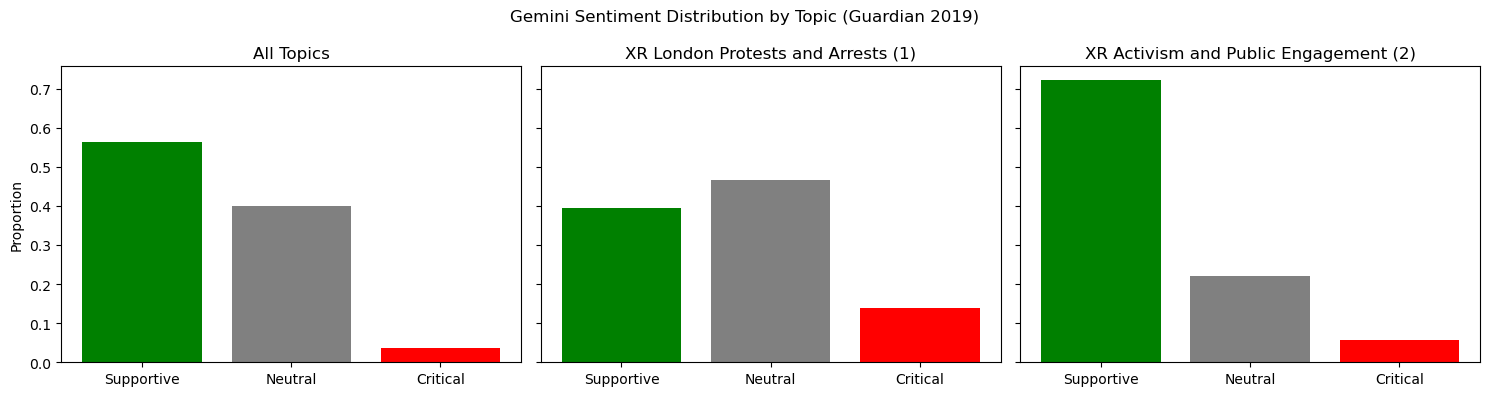

In [72]:
# Create three bar plots for sentiments across all topics, topic 1, and topic 2

# set fixed sentiment order and colors for bars
sentiment_order = ["Supportive", "Neutral", "Critical"]
colors = ["green", "grey", "red"]

# Calculate relative frequencies and adjust index according to predefined order using reindex()
overall = guardian_act_2019["Gemini_Sentiment"].value_counts(normalize=True).reindex(sentiment_order, fill_value=0)
topic1 = guardian_act_2019[guardian_act_2019["BERTopic"] == 1]["Gemini_Sentiment"]\
    .value_counts(normalize=True).reindex(sentiment_order, fill_value=0)
topic2 = guardian_act_2019[guardian_act_2019["BERTopic"] == 2]["Gemini_Sentiment"]\
    .value_counts(normalize=True).reindex(sentiment_order, fill_value=0)

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True) # shared y-axis to make comparison easier

axes[0].bar(sentiment_order, overall.values, color=colors)
axes[0].set_title("All Topics")
axes[0].set_ylabel("Proportion")

axes[1].bar(sentiment_order, topic1.values, color=colors)
axes[1].set_title("XR London Protests and Arrests (1)")

axes[2].bar(sentiment_order, topic2.values, color=colors)
axes[2].set_title("XR Activism and Public Engagement (2)")

plt.suptitle("Gemini Sentiment Distribution by Topic (Guardian 2019)")
plt.tight_layout()
plt.show()

  0%|          | 0/500 [00:00<?, ?it/s]

Resetting positions to accord with alignment


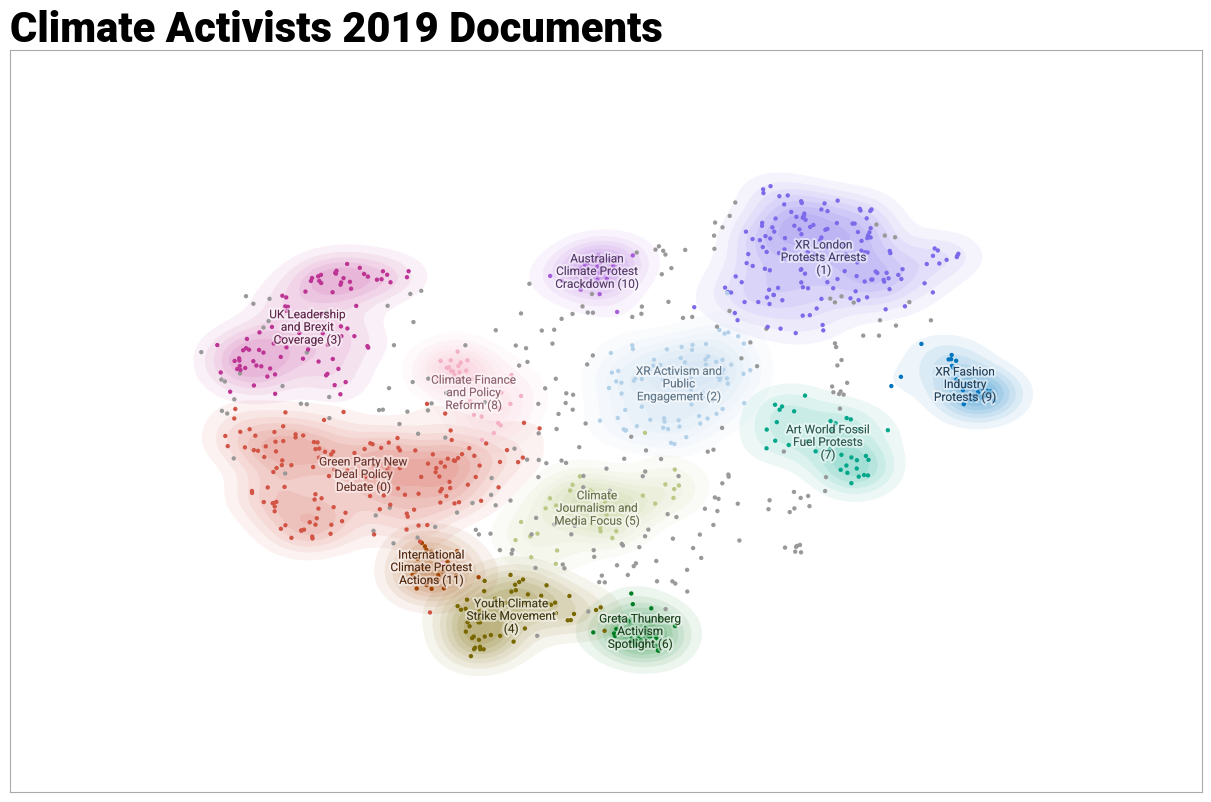

In [73]:
# visualize documents in embedded space using the datamap library which is directly accessible through BERTopic
fig = topic_model.visualize_document_datamap(docs, embeddings=embeddings, title="Climate Activists 2019 Documents", custom_labels=True, datamap_kwds={"label_over_points":True}, int_datamap_kwds={"dpi": 600}) # can do interactive=True but that messes things up
fig.show()

<h5>Document Intrusion Test</h5>

We conduct a simple intrusion test by creating samples for topics with 3 documents from said topic and one intruder. In a first iteration, the intruder is selected completely at random from all other topics. To make it more difficult, in a second step we select the intruder randomly from the 3 most similar topics to the currently selected one. The later is more likely to produce edge cases that are harder to discern.

Like for sentiment analysis validation, we use a simple combination of print statements and input() for this

In [13]:
def make_intrusion_sample(topic_id, topic_model, df, similar_topics=False, top_k_similar_topics=3):
    """
    Creates an intrusion sample of 4 documents, 3 of which belong to topic_id. The selection of the intruder 
    can be done randomly from all other topics or only from the top k most similar topics if similar_topics=True
    
    Input:
    ------
        - topic_id: int
            ID of the topic for which an intrusion sample is to be created
        
        - topic_model: bertopic._bertopic.BERTopic
            BERTopic model of which the topic is a part

        - df: pandas.core.frame.DataFrame
            Dataframe of documents. Must contain columns "BERTopic" (topic id) and "title_abstract" (text)

        - similar_topics: boolean
            If true, the intruding document will be randomly selected from the top_k_similar topics.
            Otherwise it will be selected completely at random from all other topics

        - top_k_similar_topics: int
            The range of ranked topics from which the intruder will be randomly sampled

    Return:
    -------
        - intrusion_sample: list
            List of 4 documents
        - intruder_index: int
            Index of the intruder document

    """

    unique_topics = list(topic_model.get_topics().keys()) # get all unique topics from the topics model

    # Randomly sample 3 topics from the selected topic
    true_docs =  df.loc[
        df["BERTopic"] == topic_id
    ].sample(3)["title_abstract"].to_list()
    
    # intruder topic (we also allow for outliers to appear, treat it like a normal topic)
    if similar_topics: # random intruder from the top k most similar topics (find_topics() takes in search terms and returns the most similar topics to that term. 
        # for our use case we use the topic's c-TF-IDF terms as search terms)
        similar_topics, _ = topic_model.find_topics(
        " ".join([keyword for keyword, _ in topic_model.get_topic(topic_id)]), top_n=top_k_similar_topics) # we transform the list of tuples (word, similarity_score) to just a string of the words

        intruder_topic = random.choice(similar_topics)
    else: # completely random intruders
        other_topics = [t for t in unique_topics if t != topic_id] # remove the selected topic
        intruder_topic = random.choice(other_topics) 
    
    # sample the intruder doc
    intruder_doc = df.loc[
        df["BERTopic"] == intruder_topic
    ].sample(1)["title_abstract"].iloc[0]
    
    # combine and shuffle randomly
    intrusion_sample = true_docs + [intruder_doc]
    random.shuffle(intrusion_sample)
    
    # store ground truth index
    intruder_index = intrusion_sample.index(intruder_doc)
    
    return intrusion_sample, intruder_index

In [14]:
explanations = ["", # empty explanation for outlier "topic"
                "Campaigners and politicians argue for a Green New Deal-style response that pairs emissions cuts with broader economic reform. The documents focus on policy debate, election framing, and calls for large-scale public action.",
                "This topic centers on Extinction Rebellion street protests in London, including police interventions and mass arrests. The coverage emphasizes direct action, protest bans, and confrontation with authorities.",
                "The documents mix commentary and letters about Extinction Rebellion, legal victories, and wider arguments over how to confront ecological breakdown. They frame activism as part of a broader public discussion about urgency, tactics, and accountability.", 
                "This is mainly political briefing coverage around Boris Johnson, Brexit, Labour, and leadership politics. The tone is fast-moving news roundup rather than activism itself.",
                "Young people and school students drive mass walkouts demanding action through coordinated youth strikes. Greta Thunberg and other young activists are central figures in this mobilization.",
                "Guardian commentary reflects on how environmental reporting is being shaped around the crisis and its emotional impact. The emphasis is on editorial framing, reader engagement, and the role of journalists.",
                "Greta Thunberg is the focal figure, with stories about her speeches, public profile, and cultural impact. The coverage treats her as the symbol of a youth-led movement.",
                "Artists and arts institutions are targeted over ties to BP, with protests and campaigns pushing museums to cut fossil-fuel sponsorship. The topic links cultural institutions with activist pressure and debates about legitimacy.",
                "This topic covers finance-sector responses, including central banks, investment institutions, and fossil-fuel financing. The articles argue that markets and banking policy must change to address systemic risk.",
                "Extinction Rebellion uses London Fashion Week as a target to denounce fast fashion and its environmental footprint. The coverage frames the fashion industry as a symbol of wasteful consumption and reform pressure",
                "In Queensland, officials respond to activist disruption with new police powers and tougher protest laws. The documents focus on backlash, crackdown politics, and disputes over protest legitimacy.",
                "This topic captures large-scale mobilization, with mass marches and coordinated protests tied to global summits. The coverage emphasizes turnout, organizer strategy, and disruptive public pressure."]

topic_df = topic_model.get_topic_info()
topic_df["Explanation"] = explanations

# create the title_abstract column for document creation
guardian_act_2019["title_abstract"] = guardian_act_2019["title"] + ". " + guardian_act_2019["abstract"]
# make sure BERTopic label column exists
guardian_act_2019["BERTopic"] = new_topics

# get all unique topics from the topics model
unique_topics = list(topic_model.get_topics().keys()) 
unique_topics.remove(-1) # remove the outlier "topic"

In [ ]:
# Using fully random intruder selection

correct = 0
total = 0

# iterate over all topics once
for topic_id in unique_topics:
    docs, intruder_index = make_intrusion_sample(topic_id, topic_model, guardian_act_2019, similar_topics=False) # random topics for intruders
    
    print(f"\nTopic {topic_id}")
    print(topic_df.loc[topic_df["Topic"] == topic_id, "CustomName"].values[0])
    print(topic_df.loc[topic_df["Topic"] == topic_id, "Explanation"].values[0])
    print("\nDocuments:\n")
    
    for i, doc in enumerate(docs):
        print(f"[{i}] {docs[i]}\n")
    
    # let user choose and keep track of correct guesses
    guess = int(input("Which document is the intruder? (index): "))
    print(f"Guessed: {guess}")
    print(f"Correct was: {intruder_index}")
    
    if guess == intruder_index:
        correct += 1
    
    total += 1

print(f"\nAccuracy: {correct}/{total} = {correct/total:.2f}")


Topic 0
Green Party New Deal Policy Debate (0)
Campaigners and politicians argue for a Green New Deal-style response that pairs emissions cuts with broader economic reform. The documents focus on policy debate, election framing, and calls for large-scale public action.

Documents:

[0] 'You didn't vote for me': Senator Dianne Feinstein responds to young green activists. Sunrise Movement says California senator reacted with ‘smugness and disrespect’ to their campaigning for New Green Deal

[1] UK citizens’ assembly on climate emergency announced. MPs launch assembly plan but environmental activists say its conclusions must be binding

[2] G7 and fashion houses join forces to make clothes more sustainable. Climate crisis pushes retailers to reduce their impact on the environment

[3] It’s taken years, but at last there’s real hope for meaningful climate action | Caroline Lucas. The young protesters have been inspiring. Politicians have to respond – and our Green New Deal bill will slash

In [ ]:
# Using similar topic intruder selection

correct = 0
total = 0

# iterate over all topics once
for topic_id in unique_topics:
    docs, intruder_index = make_intrusion_sample(topic_id, topic_model, guardian_act_2019, similar_topics=True) # similar topics for intruders
    
    print(f"\nTopic {topic_id}")
    print(topic_df.loc[topic_df["Topic"] == topic_id, "CustomName"].values[0])
    print(topic_df.loc[topic_df["Topic"] == topic_id, "Explanation"].values[0])
    print("\nDocuments:\n")
    
    for i, doc in enumerate(docs):
        print(f"[{i}] {docs[i]}\n")
    
    # let user choose and keep track of correct guesses
    guess = int(input("Which document is the intruder? (index): "))
    print(f"Guessed: {guess}")
    print(f"Correct was: {intruder_index}")
    
    if guess == intruder_index:
        correct += 1
    
    total += 1

print(f"\nAccuracy: {correct}/{total} = {correct/total:.2f}")


Topic 0
Green Party New Deal Policy Debate (0)
Campaigners and politicians argue for a Green New Deal-style response that pairs emissions cuts with broader economic reform. The documents focus on policy debate, election framing, and calls for large-scale public action.

Documents:

[0] Carbon emissions from energy industry rise at fastest rate since 2011. BP report reveals swings in global temperatures are increasing the use of fossil fuels

[1] ‘Try to keep up’: how Ocasio-Cortez upended politics in her first year in office. Alexandria Ocasio-Cortez, the youngest woman ever elected to Congress, did not come to play by the old rules – and she has pushed the party to the left

[2] The young Republicans breaking with their party over climate change. Millennial Trump supporters are starting to bring scientific reality to their party, but how far are they willing to go?

[3] Twitter political ad ban could silence climate activists, warns Warren. US presidential hopeful says fossil fuel fi

<h4>2025</h4>

In [11]:
guardian_act_2025 = guardian_act_df[guardian_act_df["date"].dt.year == 2025]

docs = (guardian_act_2025["title"] + ". " + guardian_act_2025["abstract"]).tolist()

embeddings = np.load("data/03_embeddings/all-MiniLM-L6-v2/guardian/2025_climate_activists_Title_Abstract_all-MiniLM-L6-v2.npy")

In [12]:
topic_model, topics, probs = fit_bertopic_model(docs, embeddings, embedding_model, min_cluster_size=15, min_samples=5)

In [ ]:
timestamps = guardian_act_2025["date"].tolist()
topics_over_time = topic_model.topics_over_time(docs, timestamps, topics=topics, nr_bins=12)

display(topic_model.get_topic_info())

topic_model.visualize_documents(
    docs,
    embeddings=embeddings,
    hide_annotations=False, 
    hide_document_hover=False 
).show()

topic_model.visualize_topics_over_time(topics_over_time, top_n_topics=10).show()

,Topic,Count,Name,Representation,KeyBERTInspired,MMR,Representative_Docs
0,-1,50,-1_protest_climate_police_coal,"[protest, climate, police, coal, world, trump,...","[climate protesters, climate protester, climat...","[coal, 2025, melbourne, crisis, letters, clima...",[Police charge 11 protesters after climate flo...
1,0,100,0_climate_activists_oil_says,"[climate, activists, oil, says, green, uk, sto...","[climate protest, climate activists, climate c...","[says, green, uk, climate activists, stop oil,...",[Youth-led Sunrise Movement to launch campaign...
2,1,41,1_trump_president_says_new,"[trump, president, says, new, labour, thing, c...","[trump, tariffs, tuesday briefing, agenda, bri...","[says, labour, climate, cuts, tariffs, morning...",[Morning Mail: Marles aide ‘in relationship wi...
3,2,37,2_palestine_action_protest_police,"[palestine, action, protest, police, arrest, p...","[protests, protest, protesters, protest group,...","[palestine, arrest, pro, says, briefing, prote...",[Met police arrest activists holding signs ref...
4,3,32,3_director_letters_people_week,"[director, letters, people, week, brown, write...","[writer, journalist, starring, director, art, ...","[brown, writer, guardian, statement, weekend, ...",[Ackroyd & Harvey: The Art of Activism review ...
5,4,18,4_summit_climate_un_talks,"[summit, climate, un, talks, trump, australia,...","[climate conference, climate action, push clim...","[summit, climate, un, talks, australia, chris,...",[Over 100 US leaders to attend Cop30 climate s...


In [14]:
guardian_act_2025["BERTopic"] = topics 

print("Relative Sentiment Distribution for Guardian Activist Data from 2019")
print("")
print("Across all Topics")
print(f"Number of articles: {len(guardian_act_2025)}")
display(round(guardian_act_2025["Gemini_Sentiment"].value_counts(normalize=True), 3))

for topic_id in range(0, 5):
    print(f"Topic {topic_id}: {", ".join(w for w, _ in topic_model.get_topic(topic_id))}")
    print(f"Number of articles: {len(guardian_act_2025[guardian_act_2025["BERTopic"] == topic_id])}")
    display(round(guardian_act_2025[guardian_act_2025["BERTopic"] == topic_id]["Gemini_Sentiment"].value_counts(normalize=True), 3))


Relative Sentiment Distribution for Guardian Activist Data from 2019

Across all Topics
Number of articles: 278


Gemini_Sentiment
Neutral       0.489
Supportive    0.486
Critical      0.025
Name: proportion, dtype: float64

Topic 0: climate, activists, oil, says, green, uk, stop, fossil, climate activists, stop oil
Number of articles: 100


Gemini_Sentiment
Supportive    0.66
Neutral       0.30
Critical      0.04
Name: proportion, dtype: float64

Topic 1: trump, president, says, new, labour, thing, climate, cuts, tariffs, mail
Number of articles: 41


Gemini_Sentiment
Neutral       0.659
Supportive    0.341
Name: proportion, dtype: float64

... (2 outputs left out)

Topic 3: director, letters, people, week, brown, writer, don, art, life, best
Number of articles: 32


Gemini_Sentiment
Neutral       0.781
Supportive    0.219
Name: proportion, dtype: float64

Topic 4: summit, climate, un, talks, trump, australia, countries, leaders, action, administration
Number of articles: 18


Gemini_Sentiment
Supportive    0.667
Neutral       0.333
Name: proportion, dtype: float64

In [15]:
# save model
topic_model.save("data/04_topic_models/guardian/2025_climate_activist", serialization="pytorch", save_ctfidf=True, save_embedding_model=embedding_model)

In [ ]:
# load back
topic_model_loaded = BERTopic.load("data/04_topic_models/guardian/2025_climate_activist", embedding_model=embedding_model)

In [16]:
print("Topic 2")
print(f"Number of articles: {len(guardian_act_2025[(guardian_act_2025["BERTopic"] == 2) & (guardian_act_2025["section_name"] != "Opinion")])}")
display(round(guardian_act_2025[(guardian_act_2025["BERTopic"] == 2) & (guardian_act_2025["section_name"] != "Opinion")]["Gemini_Sentiment"].value_counts(normalize=True), 3))


Topic 2
Number of articles: 35


Gemini_Sentiment
Neutral       0.771
Supportive    0.171
Critical      0.057
Name: proportion, dtype: float64

<h2>NYT</h2>

<h3>Sentiment Analysis</h3>

In [4]:
nyt_act_df = pd.read_csv("data/02_pre-processed/nyt_2018_2025_climate_activists.csv")
nyt_act_df["date"] = pd.to_datetime(nyt_act_df["date"])
nyt_act_df = nyt_act_df[nyt_act_df["date"].dt.year > 2018] # we are only really interested in 2019 onwards

In [5]:
df_2019 = nyt_act_df[nyt_act_df["date"].dt.year == 2019]

texts_2019_list = (df_2019["title"] + ". " + df_2019["abstract"]).tolist()

df_2025 = nyt_act_df[nyt_act_df["date"].dt.year == 2025]

texts_2025_list = (df_2025["title"] + ". " + df_2025["abstract"]).tolist()

In [ ]:
requests_per_minute = 5
labels_2019 = gemini_sentiment_analysis_activists(texts_2019_list, GEMINI_API_KEY, model="gemini-2.5-flash", batch_size=100, seconds_between_requests=60/requests_per_minute)

Awaiting Gemini response: 100%|██████████| 2/2 [01:55<00:00, 57.96s/it]


In [ ]:
requests_per_minute = 5
labels_2025 = gemini_sentiment_analysis_activists(texts_2025_list, GEMINI_API_KEY, model="gemini-2.5-flash", batch_size=100, seconds_between_requests=60/requests_per_minute)

Awaiting Gemini response: 100%|██████████| 1/1 [00:46<00:00, 47.00s/it]


In [ ]:
labels_2019_flattened = [item for sublist in labels_2019 for item in sublist]
nyt_act_df.loc[nyt_act_df["date"].dt.year == 2019 ,"Gemini_Sentiment"] = labels_2019_flattened

labels_2025_flattened = [item for sublist in labels_2025 for item in sublist]
nyt_act_df.loc[nyt_act_df["date"].dt.year == 2025 ,"Gemini_Sentiment"] = labels_2025_flattened

In [ ]:
nyt_act_df.to_csv("data/02_pre-processed/with_sentiment_analysis/nyt_2019_2025_climate_activists.csv", index=False)

In [11]:
nyt_act_df = pd.read_csv("data/02_pre-processed/with_sentiment_analysis/nyt_2019_2025_climate_activists.csv")
nyt_act_df["date"] = pd.to_datetime(nyt_act_df["date"])

In [29]:
year = 2019
year_df = nyt_act_df[nyt_act_df["date"].dt.year==year]

print(f"Rel. freq. of sentiments for {year}")

print(f"Across all ({len(year_df)} Articles)")
display(round(year_df[year_df["date"].dt.year==year]["Gemini_Sentiment"].value_counts(normalize=True), 2))

print(f"Opinion only ({len(year_df[year_df["section_name"] == "Opinion"])} Articles)")
display(round(year_df[year_df["section_name"] == "Opinion"]["Gemini_Sentiment"].value_counts(normalize=True), 2))

print(f"Non-opinion ({len(year_df[year_df["section_name"] != "Opinion"])} Articles)")
display(round(year_df[year_df["section_name"] != "Opinion"]["Gemini_Sentiment"].value_counts(normalize=True), 2))

# Note the overall low amount of articles
# Overwhelmingly neutral sentiment, similar to guardian very low amount of critical sentiment as we would expect from a left-leaning paper
# however, even opinion articles show mostly neutral sentiment -> many do not even mention activism in titles or abstrat at all

Rel. freq. of sentiments for 2019
Across all (177 Articles)


Gemini_Sentiment
Neutral       0.66
Supportive    0.31
Critical      0.04
Name: count, dtype: float64

Opinion only (36 Articles)


Gemini_Sentiment
Neutral       0.50
Supportive    0.47
Critical      0.03
Name: count, dtype: float64

Non-opinion (141 Articles)


Gemini_Sentiment
Neutral       0.70
Supportive    0.26
Critical      0.04
Name: count, dtype: float64

In [26]:
year = 2025
year_df = nyt_act_df[nyt_act_df["date"].dt.year==year]

print(f"Rel. freq. of sentiments for {year}")

print(f"Across all ({len(year_df)} Articles)")
display(round(year_df[year_df["date"].dt.year==year]["Gemini_Sentiment"].value_counts(normalize=True), 2))

print(f"Opinion only ({len(year_df[year_df["section_name"] == "Opinion"])} Articles)")
display(round(year_df[year_df["section_name"] == "Opinion"]["Gemini_Sentiment"].value_counts(normalize=True), 2))

print(f"Non-opinion ({len(year_df[year_df["section_name"] != "Opinion"])} Articles)")
display(round(year_df[year_df["section_name"] != "Opinion"]["Gemini_Sentiment"].value_counts(normalize=True), 2))

# number of articles more than cut in half
# overwhelmingly neutral sentiments, the 12 opinion pieces are all classified as neutral

Rel. freq. of sentiments for 2025
Across all (82 Articles)


Gemini_Sentiment
Neutral       0.85
Supportive    0.11
Critical      0.04
Name: count, dtype: float64

Opinion only (12 Articles)


Gemini_Sentiment
Neutral    1.0
Name: count, dtype: float64

Non-opinion (70 Articles)


Gemini_Sentiment
Neutral       0.83
Supportive    0.13
Critical      0.04
Name: count, dtype: float64

In [ ]:
# all 2025 opinion pieces are classified as neutral because none of them even discuss climate activism neither in title nor abstract
year_df[year_df["section_name"] == "Opinion"]

,id,section_name,subsection_name,date,title,url,keywords,abstract,Gemini_Sentiment
1038,nyt://article/7c24850b-64b1-53c8-b8b5-ecc20a8a...,Opinion,,2025-12-27 12:00:05+00:00,Climate Goals Are Becoming More Realistic. Tha...,https://www.nytimes.com/2025/12/27/opinion/cli...,"Global Warming, Greenhouse Gas Emissions, Alte...",Policymakers and investors are pursuing what’s...,Neutral
1040,nyt://article/28b3e69f-7f68-5ee3-a5e9-3bfa4248...,Opinion,,2025-12-18 10:02:32+00:00,The Trump Economy and America’s Bad Mood,https://www.nytimes.com/2025/12/18/opinion/the...,"Trump, Donald J, United States Economy, United...","Trump is giving himself an A-plus-plus-plus, b...",Neutral
1058,nyt://article/1684348f-95c1-5bc0-bd3a-75920388...,Opinion,,2025-09-29 09:00:23+00:00,Democrats Are in Crisis. Eat-the-Rich Populism...,https://www.nytimes.com/2025/09/29/opinion/dem...,"United States Politics and Government, Populis...","A blistering assault on economic elites, a mod...",Neutral
1061,nyt://article/110e3d7e-3766-581e-a795-06d71ad8...,Opinion,,2025-09-24 19:00:05+00:00,China’s Pivot From Green Tech Could Be Bad New...,https://www.nytimes.com/2025/09/24/opinion/chi...,"Global Warming, Solar Energy, China, United St...",China had fueled climate optimism. But now the...,Neutral
1076,nyt://article/95a6fca7-cff6-5d51-8db8-f270835f...,Opinion,,2025-06-26 09:04:31+00:00,Peter Thiel and the Antichrist,https://www.nytimes.com/2025/06/26/opinion/pet...,"Thiel, Peter A, Artificial Intelligence, Compu...","The original tech right power player on A.I., ...",Neutral
1080,nyt://article/f7a830bc-4840-5c0a-a4fa-7215cc08...,Opinion,,2025-06-15 10:00:05+00:00,A Bold Idea to Raise the Birthrate: Make Paren...,https://www.nytimes.com/2025/06/15/opinion/bir...,"Parenting, Birth Rates, Women and Girls, Unite...",At least we know what’s definitely not working.,Neutral
1089,nyt://article/0938fcf4-a709-5bb3-b40c-5a8123b5...,Opinion,,2025-05-21 09:02:03+00:00,JD Vance on His Faith and Trump’s Most Controv...,https://www.nytimes.com/2025/05/21/opinion/jd-...,"audio-neutral-informative, Vance, J D, Roman C...",The vice president joins Ross Douthat in Rome ...,Neutral
1100,nyt://article/12819da6-148c-53fb-9df6-c7670894...,Opinion,,2025-04-14 09:02:05+00:00,Larry Summers on Trump: ‘The First Rule of Hol...,https://www.nytimes.com/2025/04/14/opinion/lar...,"audio-neutral-informative, Customs (Tariff), T...",The former treasury secretary on the president...,Neutral
1107,nyt://article/e2c96a54-cbd9-56e1-9f3e-dfa9e452...,Opinion,,2025-03-12 09:02:16+00:00,Why Trump’s Tariffs Won’t Work,https://www.nytimes.com/2025/03/12/opinion/ezr...,"Trump, Donald J, Customs (Tariff), Internation...",The economist Kimberly Clausing explains the p...,Neutral
1112,nyt://article/b999f3cf-9c20-5cdd-a1df-81ad4f69...,Opinion,,2025-02-17 10:02:27+00:00,My Values ‘Can’t Be Nullified by an Executive ...,https://www.nytimes.com/2025/02/17/opinion/ref...,"audio-neutral-informative, Immigration and Emi...",A former U.S.A.I.D. worker talks with the colu...,Neutral


<h3>Named Entity Recognition</h3>

In [90]:
nyt_act_df = pd.read_csv("data/02_pre-processed/with_sentiment_analysis/nyt_2019_2025_climate_activists.csv")
nyt_act_df["date"] = pd.to_datetime(nyt_act_df["date"])

In [91]:
nyt_act_df["entities_title_abstract"] = (nyt_act_df["title"] + nyt_act_df["abstract"]).apply(lambda text: extract_entities(text, nlp))
nyt_act_df["entities_title_abstract"] = nyt_act_df["entities_title_abstract"].apply(merge_xr_abbreviation)

In [48]:
nyt_act_df.to_csv("data/02_pre-processed/with_sentiment_analysis/with_ner/nyt_2019_2025_climate_activists.csv", index=False)

In [38]:
nyt_act_df = pd.read_csv("data/02_pre-processed/with_sentiment_analysis/with_ner/nyt_2019_2025_climate_activists.csv")
nyt_act_df["date"] = pd.to_datetime(nyt_act_df["date"])

In [46]:
nyt_act_df.explode("entities_title_abstract").groupby(["entities_title_abstract"]).size().sort_values(ascending=False)

entities_title_abstract
(Biden, PERSON)               138
(Trump, PERSON)                65
(U.S., GPE)                    30
(Greta Thunberg, PERSON)       23
(U.N., ORG)                    23
                             ... 
(Jamie RaskinThe, PERSON)       1
(Jamie Reid, PERSON)            1
(Jane F. McAlevey, PERSON)      1
(Janet Yellen, PERSON)          1
(van Gogh’s, PERSON)            1
Length: 793, dtype: int64

In [ ]:
# top entities filtered for only persons and organizations

entity_types_of_interest = ["PERSON", "ORG"] #, "GPE"]
entities_to_ignore = ["Times"] # we ignore mentions of the newspaper istelf

df_exploded = nyt_act_df.explode("entities_title_abstract") # explode the list of entities (separate row for each entry)
df_exploded = df_exploded[df_exploded["entities_title_abstract"].notna()] # drop rows with no detected entities
df_filtered = df_exploded[df_exploded["entities_title_abstract"].apply(lambda x: x[1] in entity_types_of_interest and x[0] not in entities_to_ignore)] # filter for PERSON and ORG entities
df_filtered["entity"] = df_filtered["entities_title_abstract"].apply(lambda x: x[0]) # extract just the entity text

# show number of occurences
display(df_filtered.groupby("entity").size().sort_values(ascending=False))

# mostly political actors

# XR gets 10 mentions, the most mentioned american group is the Sunrise Movement at 6 mentions
# this is extremely low, considering we are looking at the entire 2019-2025 year range

entity
Biden              149
Trump               65
Greta Thunberg      23
U.N.                23
Senate              21
                  ... 
Honor Titus          1
Hollywood            1
Hillary Clinton      1
Hezbollah            1
van Gogh’s           1
Length: 626, dtype: int64

<h3>Embeddings</h3>

In [ ]:
embedding_model = SentenceTransformer("all-MiniLM-L6-v2") 

In [ ]:
# guardian activist data using MiniLM which is really quick (extremely lightweight)
for year in range(2019, 2026):
    df = nyt_act_df[nyt_act_df["date"].dt.year == year].copy()
    docs = (df["title"] + ". " + df["abstract"]).tolist()

    embeddings = embedding_model.encode(
        docs,
        show_progress_bar=True,
        batch_size=32       
    )

    np.save(f"data/03_embeddings/all-MiniLM-L6-v2/nyt/{year}_climate_activists_Title_Abstract_all-MiniLM-L6-v2.npy", embeddings)

<h3>Topic Modeling</h3>

In [50]:
nyt_act_df = pd.read_csv("data/02_pre-processed/with_sentiment_analysis/with_ner/nyt_2019_2025_climate_activists.csv")
nyt_act_df["date"] = pd.to_datetime(nyt_act_df["date"])

<h4>2019</h4>

In [51]:
nyt_act_2019 = nyt_act_df[nyt_act_df["date"].dt.year == 2019]

docs = (nyt_act_2019["title"] + ". " + nyt_act_2019["abstract"]).tolist()

embeddings = np.load("data/03_embeddings/all-MiniLM-L6-v2/nyt/2019_climate_activists_Title_Abstract_all-MiniLM-L6-v2.npy")

In [21]:
topic_model, topics, probs = fit_bertopic_model(docs, embeddings, embedding_model, min_cluster_size=10, min_samples=5)

In [ ]:
timestamps = nyt_act_2019["date"].tolist()
topics_over_time = topic_model.topics_over_time(docs, timestamps, topics=topics, nr_bins=12)


display(topic_model.get_topic_info())

topic_model.visualize_documents(
    docs,
    embeddings=embeddings,
    hide_annotations=False,  
    hide_document_hover=False  
).show()

topic_model.visualize_topics_over_time(topics_over_time, top_n_topics=10).show()

,Topic,Count,Name,Representation,KeyBERTInspired,MMR,Representative_Docs
0,-1,23,-1_new_europe_oil_people,"[new, europe, oil, people, latest, future, dem...","[climate change, climate, climate week, emissi...","[europe, people, future, heard, oil gas, week,...",[The Arts Are Shunning Big Oil. The Salzburg F...
1,0,114,0_climate_change_climate change_new,"[climate, change, climate change, new, action,...","[climate activism, climate activists, climate ...","[change, week, protests, london, action climat...","[Telling Stories to Battle Climate Change, Wit..."
2,1,16,1_need know_need_know_friday,"[need know, need, know, friday, trump, brexit,...","[brexit, politics, president trump, trump, uni...","[brexit, trade, let, military, summit, takeawa...","[New Zealand, North Korea, Facebook: Your Frid..."
3,2,13,2_deal_green new_new deal_green,"[deal, green new, new deal, green, new, senate...","[new deal, green new, climate change, climate ...","[new deal, green, senate, ups, radical, genera...",[House Democrats Offer an Alternative to the G...
4,3,11,3_democratic_democrats_movement_green,"[democratic, democrats, movement, green, corte...","[climate activists, green parties, democrats, ...","[democrats, ocasio cortez, left, young climate...",[Progressive Activists Have Pushed Democrats t...


In [23]:
# save model
topic_model.save("data/04_topic_models/nyt/2019_climate_activist", serialization="pytorch", save_ctfidf=True, save_embedding_model=embedding_model)

In [ ]:
# load back
topic_model_loaded = BERTopic.load("data/04_topic_models/nyt/2019_climate_activist", embedding_model=embedding_model)

<h4>2025</h4>

In [53]:
nyt_act_2025 = nyt_act_df[nyt_act_df["date"].dt.year == 2025]

docs = (nyt_act_2025["title"] + ". " + nyt_act_2025["abstract"]).tolist()

embeddings = np.load("data/03_embeddings/all-MiniLM-L6-v2/nyt/2025_climate_activists_Title_Abstract_all-MiniLM-L6-v2.npy")

In [25]:
topic_model, topics, probs = fit_bertopic_model(docs, embeddings, embedding_model, min_cluster_size=5, min_samples=5)

In [ ]:
timestamps = nyt_act_2025["date"].tolist()
topics_over_time = topic_model.topics_over_time(docs, timestamps, topics=topics, nr_bins=12)

display(topic_model.get_topic_info())

topic_model.visualize_documents(
    docs,
    embeddings=embeddings,
    hide_annotations=False, 
    hide_document_hover=False  
).show()

topic_model.visualize_topics_over_time(topics_over_time, top_n_topics=10).show()

# extremely low amount of articles, topic modeling makes little sense at this stage

,Topic,Count,Name,Representation,KeyBERTInspired,MMR,Representative_Docs
0,-1,41,-1_new_climate_york_new york,"[new, climate, york, new york, gas, world, tru...","[climate activism, climate policies, climate c...","[new york, hochul, trump administration, chang...",[Hochul Repeals Rule Allowing New Customers Fr...
1,0,19,0_climate_trump_china_president,"[climate, trump, china, president, global, ene...","[climate policy, climate policies, climate cha...","[china, energy, moves, week, global warming, t...",[The Trump Administration Is Dismantling Clima...
2,1,9,1_trump_trump tariffs_tariffs_costs,"[trump, trump tariffs, tariffs, costs, bad, am...","[trump tariffs, tariffs, trump, billionaire, i...","[trump tariffs, bad, president, investors, hig...",[The Trump Economy and America’s Bad Mood. Tru...
3,2,8,2_day_night_activists_earth,"[day, night, activists, earth, climate activis...","[climate activism, climate activists, climate ...","[climate activists, fans, high profile, earlie...",[The Old Climate-Activism Playbook No Longer W...
4,3,5,3_orders_young_executive_people,"[orders, young, executive, people, companies, ...","[climate activists, suing, climate change, glo...","[orders, young, executive, trump, suing, fuel,...",[Young People Suing Trump Over Climate Have Th...


In [27]:
# save model
topic_model.save("data/04_topic_models/nyt/2025_climate_activist", serialization="pytorch", save_ctfidf=True, save_embedding_model=embedding_model)

In [ ]:
# load back
topic_model_loaded = BERTopic.load("data/04_topic_models/nyt/2025_climate_activist", embedding_model=embedding_model)

<h2>Validation of Sentiment Analysis</h2>

We use human annotation for a rudimentary validation of our approach by, again, using a simple combination of prints and input()

In [29]:
guardian_act_df = pd.read_csv("data/02_pre-processed/with_sentiment_analysis/guardian_2010_2026_climate_activists.csv")
nyt_act_df = pd.read_csv("data/02_pre-processed/with_sentiment_analysis/nyt_2019_2025_climate_activists.csv")
full_df = pd.concat([guardian_act_df[~(guardian_act_df["Gemini_Sentiment"].isna())], nyt_act_df[~(nyt_act_df["Gemini_Sentiment"].isna())]])

In [31]:
random_state = 42
# validate across 60 (20*3) using stratified sampling with equal size groups since "Critical" is so underrepresented (massive class imbalance)
equal_sample_size = 20
balanced_sample = pd.concat([full_df[full_df["Gemini_Sentiment"] == "Supportive"].sample(equal_sample_size, random_state=random_state), full_df[full_df["Gemini_Sentiment"] == "Neutral"].sample(equal_sample_size, random_state=random_state), full_df[full_df["Gemini_Sentiment"] == "Critical"].sample(equal_sample_size, random_state=random_state)])
balanced_sample = balanced_sample.sample(frac=1) # shuffle randomly (just changes sorting while keeping full data)

In [32]:
# dictionary of possible inputs to avoid full label type out on every input
choices = {
    "1": "Supportive",
    "2": "Neutral",
    "3": "Critical"
} 

balanced_sample["Manual_Annotation"] = ""

i = 0
while i < len(balanced_sample): # we use this manual index loop instead of iterrows() to allow moving back and forth between rows/indices

    row = balanced_sample.iloc[i]

    print("\n")
    print(f"Loc {i}")
    print("Title:", row["title"])
    print("Abstract:", row["abstract"])

    selection = ""
    while selection not in choices and selection != "b": # wait for a valid input
        selection = input("(1/2/3 or b): ").strip().lower()

    # if we select to go back we move minus one index (sometimes print does not show before input window so this is helpful for making corrections)
    if selection == "b":
        if i > 0: # only allow going back if it's not the first item currently
            i -= 1
            print("\nPrevious item:")
        else:
            print("\nFirst item can't go back")
        continue


    label = choices[selection] # translate 1/2/3 into label
    balanced_sample.loc[balanced_sample.index[i], "Manual_Annotation"] = label # set row value
    print(f"\nManual Annotation: {label}")

    i+=1 # move to next index/row



Loc 0
Title: How we saw America in 2019 – Guardian US's favorite photographs
Abstract: The photographers Guardian US worked with treated each story with care and creativity, making images that provide a stunning view of the past year

Manual Annotation: Neutral


Loc 1
Title: Brexit, Trump, Serbia: Your Friday Briefing
Abstract: Let us help you start your day.

Manual Annotation: Neutral


Loc 2
Title: Extinction Rebellion’s right to protest must be respected | Letters
Abstract: Letters: Campaigners and MPs condemn the ban of Extinction Rebellion across London, while Keith Flett writes that historically protest has always included disruptive elements. Plus letters from Marilyn Mason, Richard Terry, Declan O’Neill, Jackie Ambrose and Peter B Baker

Manual Annotation: Supportive


Loc 3
Title: Extinction Rebellion and Attenborough put climate in spotlight
Abstract: News bulletins are leading on global warming and the BBC is shedding some of its ‘balance’

Manual Annotation: Supportive


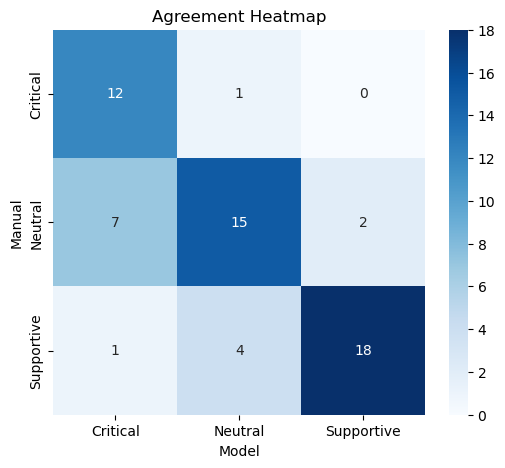

Accuracy: 0.75


In [33]:
# create a matrix for evaluation

agreement_matrix = pd.crosstab(
    balanced_sample["Manual_Annotation"],
    balanced_sample["Gemini_Sentiment"],
    rownames=["Manual"],
    colnames=["Model"]
)
agreement_matrix

plt.figure(figsize=(6, 5))
sns.heatmap(
    agreement_matrix,
    annot=True,
    cmap="Blues"
)
plt.title("Agreement Heatmap")
plt.show()

accuracy = (balanced_sample["Manual_Annotation"] 
            == balanced_sample["Gemini_Sentiment"]).mean()
print(f"Accuracy: {accuracy}")

# Accuracy is acceptable